# PlantVillage Dataset — Full Pipeline: Cleaning, EDA & Preprocessing

## Roadmap

| Part | Sections | What it does |
|---|---|---|
| **Part 1** | 1–12 | Inventory, image integrity and quality audit, duplicate detection, cleaning decisions, export. Produces `final_df` (the cleaned dataset). |
| **Part 1B** | E1–E8 | EDA on the data itself (crop, disease and class labels), computed on `final_df`. |
| **Part 2** | 13–21 | Preprocessing: duplicate groups, stratified group split, normalization, class weights, augmentation, export. |

Run the notebook top to bottom. Part 1B and Part 2 both depend on the files and variables produced by Part 1.

## 1. Environment Setup

In [11]:
from pathlib import Path
import hashlib
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import imagehash
from datasets import load_dataset, DatasetDict, concatenate_datasets
import requests
from urllib.parse import quote
from IPython.display import display
from PIL import Image, ImageOps
from tqdm.auto import tqdm

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

# ---- Dataset source ----
DATASET_ID = "mohanty/PlantVillage"
DATASET_CONFIG = "default"  # informational only; do not pass as a config argument

# Images are cached locally only as working copies for this notebook.
IMAGE_CACHE_DIR = Path.home() / ".cache" / "plantvillage_pipeline_images"
IMAGE_CACHE_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR = Path("reports")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
EXPECTED_IMAGE_COUNT = 54305  # expected RGB/color subset, not all three variants

print("Dataset source:", DATASET_ID)
print("Selected subset: raw/color only")
print("Image working cache:", IMAGE_CACHE_DIR)
print("Output directory:", OUTPUT_DIR.resolve())


Dataset source: mohanty/PlantVillage
Selected subset: raw/color only
Image working cache: C:\Users\omarw\.cache\plantvillage_pipeline_images
Output directory: C:\Users\omarw\Downloads\reports


## 2. Import PlantVillage from Hugging Face

In [12]:
from datasets import DatasetDict, load_dataset, concatenate_datasets

DATASET_ID = "mohanty/PlantVillage"
EXPECTED_IMAGE_COUNT = 54305

# Load the only available Hugging Face configuration.
# IMPORTANT: "color" is a folder category in the path, NOT a dataset config.
dataset = load_dataset(DATASET_ID, name="default")

print("Dataset ID:", DATASET_ID)
print("Available splits/config:", dataset)

# Check the schema before filtering so a missing path column gives a clear error.
if isinstance(dataset, DatasetDict):
    split_names = list(dataset.keys())
    first_split = dataset[split_names[0]]
else:
    split_names = ["default"]
    first_split = dataset

if "text" not in first_split.column_names:
    raise ValueError(
        "Expected a 'text' column containing image paths. "
        f"Available columns: {first_split.column_names}"
    )

def is_color_record(row):
    # HF stores relative paths such as raw/color/Class_Name/image.jpg.
    value = str(row["text"]).replace("\\\\", "/").replace("\\", "/").lstrip("/")
    parts = [part for part in value.split("/") if part]
    return len(parts) >= 3 and parts[0].lower() == "raw" and parts[1].lower() == "color"

# Filter each split BEFORE combining or downloading images.
# Keep the train/test assignment as a column so it survives concatenation.
if isinstance(dataset, DatasetDict):
    color_parts = {}
    for split_name, split_data in dataset.items():
        filtered = split_data.filter(
            is_color_record,
            desc=f"Filtering {split_name}: raw/color"
        )
        filtered = filtered.add_column("split", [split_name] * len(filtered))
        color_parts[split_name] = filtered
        print(f"{split_name}: {len(split_data):,} total rows -> {len(filtered):,} raw/color rows")

    color_dataset = DatasetDict(color_parts)
    nonempty_color_parts = [part for part in color_dataset.values() if len(part) > 0]
    if not nonempty_color_parts:
        raise ValueError("No raw/color paths were found in the default Hugging Face dataset.")

    dataset_all = (
        concatenate_datasets(nonempty_color_parts)
        if len(nonempty_color_parts) > 1
        else nonempty_color_parts[0]
    )
else:
    filtered = dataset.filter(is_color_record, desc="Filtering default: raw/color")
    color_dataset = DatasetDict({
        "default": filtered.add_column("split", ["default"] * len(filtered))
    })
    dataset_all = color_dataset["default"]
    print(f"default: {len(dataset):,} total rows -> {len(dataset_all):,} raw/color rows")

print("\\nSplits checked:", split_names)
print("Rows retained for raw/color:", f"{len(dataset_all):,}")
print("Columns:", dataset_all.column_names)

if len(dataset_all) == 0:
    raise ValueError("The raw/color subset is empty; stop before importing images.")

print("First color row:", dataset_all[0])

# Confirm every retained record belongs to raw/color.
from collections import Counter
variant_counts = Counter()
for row in dataset_all:
    normalized = str(row["text"]).replace("\\\\", "/").replace("\\", "/").lstrip("/")
    parts = [part for part in normalized.split("/") if part]
    variant_counts["/".join(parts[:2]) if len(parts) >= 2 else "unknown"] += 1

print("\\nImage variants retained:")
for variant, count in sorted(variant_counts.items()):
    print(f"{variant}: {count:,}")

if set(variant_counts) != {"raw/color"}:
    raise ValueError(f"Unexpected image variants after filtering: {dict(variant_counts)}")

if len(dataset_all) != EXPECTED_IMAGE_COUNT:
    print(
        f"WARNING: expected {EXPECTED_IMAGE_COUNT:,} raw/color rows, "
        f"but found {len(dataset_all):,}. The notebook will use the actual filtered count."
    )
else:
    print("Count check passed: exactly 54,305 raw/color rows.")


Dataset ID: mohanty/PlantVillage
Available splits/config: DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 129783
    })
    test: Dataset({
        features: ['text'],
        num_rows: 33133
    })
})
train: 129,783 total rows -> 43,596 raw/color rows
test: 33,133 total rows -> 10,709 raw/color rows
\nSplits checked: ['train', 'test']
Rows retained for raw/color: 54,305
Columns: ['text', 'split']
First color row: {'text': 'raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG', 'split': 'train'}
\nImage variants retained:
raw/color: 54,305
Count check passed: exactly 54,305 raw/color rows.


In [13]:
# Safety check: the import stage must receive only raw/color paths.
# This cell does not load or download images; it verifies the filtered inventory.
from collections import Counter

variant_counts = Counter()
for row in dataset_all:
    normalized = str(row["text"]).replace("\\\\", "/").replace("\\", "/").lstrip("/")
    parts = [part for part in normalized.split("/") if part]
    variant = "/".join(parts[:2]) if len(parts) >= 2 else "unknown"
    variant_counts[variant] += 1

print("Image variants returned by the Hugging Face dataset:")
for variant, count in sorted(variant_counts.items()):
    print(f"{variant}: {count:,}")

assert set(variant_counts).issubset({"raw/color"}), (
    "Non-color image paths remain in dataset_all. Re-run the import/filter cells."
)
print(f"\\nImages queued for import: {len(dataset_all):,} (raw/color only)")


Image variants returned by the Hugging Face dataset:
raw/color: 54,305
\nImages queued for import: 54,305 (raw/color only)


In [14]:
from collections import Counter

def get_counts(split):
    return Counter(
        row["text"].replace("\\", "/").split("/")[2]
        for row in color_dataset[split]
    )

train_counts = get_counts("train")
test_counts = get_counts("test")

print("Train:", sum(train_counts.values()), "images |", len(train_counts), "classes")
print("Test: ", sum(test_counts.values()), "images |", len(test_counts), "classes")

print("\nClasses missing from test:")
print(sorted(set(train_counts) - set(test_counts)))

print("\nTrain min/max:", min(train_counts.values()), max(train_counts.values()))
print("Test min/max: ", min(test_counts.values()), max(test_counts.values()))

Train: 43596 images | 38 classes
Test:  10709 images | 38 classes

Classes missing from test:
[]

Train min/max: 120 4527
Test min/max:  32 1100


## 3. Import PlantVillage from Hugging Face

In [15]:
from pathlib import Path
import hashlib
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import imagehash
from IPython.display import display
from PIL import Image, ImageOps
from tqdm.auto import tqdm

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

# ---- Configuration ----
DATA_DIR = Path(
        r"C:\Users\omarw\Downloads\PlantVillage-Dataset-master\PlantVillage-Dataset-master\raw\color"
)
OUTPUT_DIR = Path("reports")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
EXPECTED_IMAGE_COUNT = 54305

print("Dataset directory:", DATA_DIR)
print("Directory exists:", DATA_DIR.exists())
print("Output directory:", OUTPUT_DIR.resolve())


Dataset directory: C:\Users\omarw\Downloads\PlantVillage-Dataset-master\PlantVillage-Dataset-master\raw\color
Directory exists: True
Output directory: C:\Users\omarw\Downloads\reports


In [16]:
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset directory not found: {DATA_DIR}\n"
        "Update DATA_DIR to the folder containing the PlantVillage class directories."
    )

class_folders = sorted(folder for folder in DATA_DIR.iterdir() if folder.is_dir())

image_paths = sorted(
    path
    for folder in class_folders
    for path in folder.rglob("*")
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
)


def get_class_name(image_path):
    # Top-level class folder under DATA_DIR
    return Path(image_path).relative_to(DATA_DIR).parts[0]


inventory_df = pd.DataFrame({
    "path": [str(p) for p in image_paths],
    "relative_path": [str(p.relative_to(DATA_DIR)) for p in image_paths],
    "filename": [p.name for p in image_paths],
    "class": [get_class_name(p) for p in image_paths],
    "extension": [p.suffix.lower() for p in image_paths],
    "file_size_bytes": [p.stat().st_size for p in image_paths],
})

if inventory_df.empty:
    raise ValueError("No supported images were found. Check DATA_DIR.")

print("DATASET INVENTORY")
print("=" * 45)
print("Class folders:", len(class_folders))
print("Images found:", f"{len(inventory_df):,}")
print("Expected reference count:", f"{EXPECTED_IMAGE_COUNT:,}")
print("Count matches expected:", len(inventory_df) == EXPECTED_IMAGE_COUNT)

display(inventory_df.head())

DATASET INVENTORY
Class folders: 38
Images found: 54,305
Expected reference count: 54,305
Count matches expected: True


,path,relative_path,filename,class,extension,file_size_bytes
0,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Apple___Apple_scab\00075aa8-d81a-4184-8541-b69...,00075aa8-d81a-4184-8541-b692b78d398a___FREC_Sc...,Apple___Apple_scab,.jpg,9616
1,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Apple___Apple_scab\01a66316-0e98-4d3b-a56f-d78...,01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Sc...,Apple___Apple_scab,.jpg,10108
2,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Apple___Apple_scab\01f3deaa-6143-4b6c-9c22-620...,01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Sc...,Apple___Apple_scab,.jpg,12005
3,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Apple___Apple_scab\0208f4eb-45a4-4399-904e-989...,0208f4eb-45a4-4399-904e-989ac2c6257c___FREC_Sc...,Apple___Apple_scab,.jpg,19474
4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Apple___Apple_scab\023123cb-7b69-4c9f-a521-766...,023123cb-7b69-4c9f-a521-766d7c8543bb___FREC_Sc...,Apple___Apple_scab,.jpg,8897


## 4. Class Distribution (raw inventory)
### Objective
Count the images per class in the raw inventory, before any cleaning. The full class-distribution and imbalance analysis is done on the cleaned dataset in **Part 1B (EDA)**, so the chart and imbalance summary are not repeated here.

In [17]:
class_distribution_df = (
    inventory_df["class"]
    .value_counts()
    .rename_axis("class")
    .reset_index(name="image_count")
)
class_distribution_df["percentage"] = (
    class_distribution_df["image_count"] / len(inventory_df) * 100
)

print("Total classes:", len(class_distribution_df))
print("Total images:", int(class_distribution_df["image_count"].sum()))
display(class_distribution_df.round({"percentage": 3}))

Total classes: 38
Total images: 54305


,class,image_count,percentage
0,Orange___Haunglongbing_(Citrus_greening),5507,10.141
1,Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357,9.865
2,Soybean___healthy,5090,9.373
3,Peach___Bacterial_spot,2297,4.230
4,Tomato___Bacterial_spot,2127,3.917
5,Tomato___Late_blight,1909,3.515
6,Squash___Powdery_mildew,1835,3.379
7,Tomato___Septoria_leaf_spot,1771,3.261
8,Tomato___Spider_mites Two-spotted_spider_mite,1676,3.086
9,Apple___healthy,1645,3.029


## 5. Image Integrity and Dimensions
### Objective
### 5.1 Validate Every Image

In [18]:
image_info = []

for path_string in tqdm(inventory_df["path"], desc="Validating images"):
    info = {
        "image_format": None,
        "mode": None,
        "width": np.nan,
        "height": np.nan,
        "status": "valid",
        "error": None,
    }
    try:
        if Path(path_string).stat().st_size == 0:
            raise ValueError("Zero-byte file")

        with Image.open(path_string) as img:
            img.verify()

        # Reopen and force pixel decoding after verify()
        with Image.open(path_string) as img:
            img.load()
            info["image_format"] = img.format
            info["mode"] = img.mode
            info["width"], info["height"] = ImageOps.exif_transpose(img).size

    except Exception as exc:
        info["status"] = "invalid"
        info["error"] = f"{type(exc).__name__}: {exc}"

    image_info.append(info)

validation_df = pd.concat([inventory_df, pd.DataFrame(image_info)], axis=1)

valid_df = validation_df[validation_df["status"] == "valid"].copy()
invalid_df = validation_df[validation_df["status"] == "invalid"].copy()

print("Images scanned:", len(validation_df))
print("Readable images:", len(valid_df))
print("Unreadable images:", len(invalid_df))

print("\nImage modes:")
display(validation_df["mode"].value_counts(dropna=False))

print("\nImage extensions:")
display(validation_df["extension"].value_counts())

print("\nInvalid images (first 20):")
display(invalid_df[["relative_path", "file_size_bytes", "error"]].head(20))

Validating images: 100%|██████████| 54305/54305 [01:06<00:00, 818.33it/s] 


Images scanned: 54305
Readable images: 54305
Unreadable images: 0

Image modes:


mode
RGB     54304
RGBA        1
Name: count, dtype: int64


Image extensions:


extension
.jpg     54303
.png         1
.jpeg        1
Name: count, dtype: int64


Invalid images (first 20):


,relative_path,file_size_bytes,error


### 5.2 Dimension and Aspect-Ratio Statistics

In [19]:
valid_df["aspect_ratio"] = valid_df["width"] / valid_df["height"]
valid_df["total_pixels"] = valid_df["width"] * valid_df["height"]
valid_df["megapixels"] = valid_df["total_pixels"] / 1_000_000

print("IMAGE DIMENSIONS SUMMARY")
print("=" * 50)
display(
    valid_df[["width", "height", "aspect_ratio", "total_pixels", "megapixels"]]
    .describe().round(3)
)

# Most common image sizes
size_distribution_df = (
    valid_df
    .groupby(["width", "height"])
    .size()
    .reset_index(name="image_count")
    .sort_values("image_count", ascending=False)
)

print("\nMost common image dimensions:")
display(size_distribution_df.head(15))
print("Number of unique dimensions:", len(size_distribution_df))

# Aspect-ratio distribution
print("\nASPECT RATIO DISTRIBUTION")
print("=" * 50)
display(
    valid_df["aspect_ratio"]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .to_frame()
)

# Resolution outliers (IQR rule)
Q1 = valid_df["total_pixels"].quantile(0.25)
Q3 = valid_df["total_pixels"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = max(0, Q1 - 1.5 * IQR)
upper_bound = Q3 + 1.5 * IQR

valid_df["resolution_outlier"] = (
    (valid_df["total_pixels"] < lower_bound)
    | (valid_df["total_pixels"] > upper_bound)
)

print("\nRESOLUTION OUTLIER ANALYSIS")
print("=" * 50)
print("Lower bound:", round(lower_bound))
print("Upper bound:", round(upper_bound))
print("Potential resolution outliers:", int(valid_df["resolution_outlier"].sum()))

# Class-level resolution statistics
class_resolution_stats = (
    valid_df
    .groupby("class")
    .agg(
        image_count=("filename", "count"),
        mean_width=("width", "mean"),
        mean_height=("height", "mean"),
        mean_megapixels=("megapixels", "mean"),
        min_megapixels=("megapixels", "min"),
        max_megapixels=("megapixels", "max"),
        unique_dimensions=("total_pixels", "nunique"),
    )
    .sort_values("mean_megapixels", ascending=False)
)

print("\nCLASS-LEVEL RESOLUTION STATISTICS")
display(class_resolution_stats.round(3))

IMAGE DIMENSIONS SUMMARY


,width,height,aspect_ratio,total_pixels,megapixels
count,54305.0,54305.0,54305.0,54305.0,54305.000
mean,256.0,256.0,1.0,65536.0,0.066
std,0.0,0.0,0.0,0.0,0.000
min,256.0,256.0,1.0,65536.0,0.066
25%,256.0,256.0,1.0,65536.0,0.066
50%,256.0,256.0,1.0,65536.0,0.066
75%,256.0,256.0,1.0,65536.0,0.066
max,256.0,256.0,1.0,65536.0,0.066



Most common image dimensions:


,width,height,image_count
0,256,256,54305


Number of unique dimensions: 1

ASPECT RATIO DISTRIBUTION


,aspect_ratio
count,54305.0
mean,1.0
std,0.0
min,1.0
1%,1.0
5%,1.0
25%,1.0
50%,1.0
75%,1.0
95%,1.0



RESOLUTION OUTLIER ANALYSIS
Lower bound: 65536
Upper bound: 65536
Potential resolution outliers: 0

CLASS-LEVEL RESOLUTION STATISTICS


,image_count,mean_width,mean_height,mean_megapixels,min_megapixels,max_megapixels,unique_dimensions
class,,,,,,,
Apple___Apple_scab,630,256.0,256.0,0.066,0.066,0.066,1
Apple___Black_rot,621,256.0,256.0,0.066,0.066,0.066,1
Apple___Cedar_apple_rust,275,256.0,256.0,0.066,0.066,0.066,1
Apple___healthy,1645,256.0,256.0,0.066,0.066,0.066,1
Blueberry___healthy,1502,256.0,256.0,0.066,0.066,0.066,1
Cherry_(including_sour)___Powdery_mildew,1052,256.0,256.0,0.066,0.066,0.066,1
Cherry_(including_sour)___healthy,854,256.0,256.0,0.066,0.066,0.066,1
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,513,256.0,256.0,0.066,0.066,0.066,1
Corn_(maize)___Common_rust_,1192,256.0,256.0,0.066,0.066,0.066,1


### 5.3 Dimension Distributions

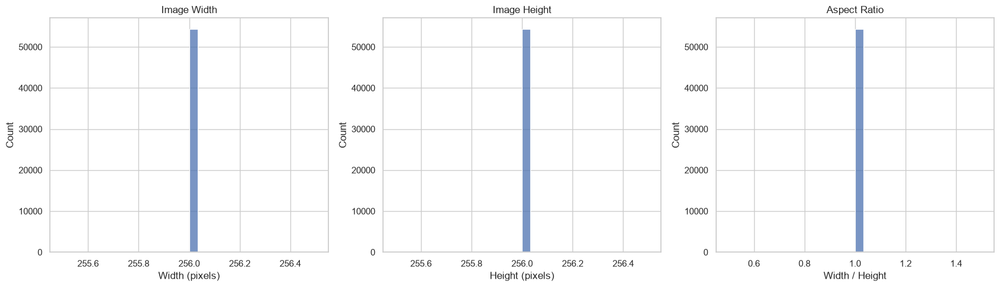

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.histplot(valid_df["width"], bins=30, ax=axes[0])
axes[0].set_title("Image Width")
axes[0].set_xlabel("Width (pixels)")

sns.histplot(valid_df["height"], bins=30, ax=axes[1])
axes[1].set_title("Image Height")
axes[1].set_xlabel("Height (pixels)")

sns.histplot(valid_df["aspect_ratio"], bins=30, ax=axes[2])
axes[2].set_title("Aspect Ratio")
axes[2].set_xlabel("Width / Height")

plt.tight_layout()
plt.show()

## Pixel-Level Measurements (Quality and Color)
### Objective
### Metrics
- **Brightness:** mean grayscale pixel intensity (0–255).
- **Contrast:** standard deviation of grayscale intensity.
- **Dark-pixel percentage:** percentage of grayscale pixels at or below 10.
- **Bright-pixel percentage:** percentage of grayscale pixels at or above 245.
- **Saturation:** mean HSV saturation (0–255).
- **Sharpness proxy:** variance of a 4-neighbor Laplacian response. Low values may indicate blur, but image content and texture also affect th
- **Mean RGB:** mean red, green, and blue channel values. These are descriptive summaries and not disease indicators on their own.

In [21]:
quality_records = []

for path_string, class_name, filename in tqdm(
    zip(valid_df["path"], valid_df["class"], valid_df["filename"]),
    total=len(valid_df),
    desc="Measuring images"
):
    record = {
        "class": class_name,
        "filename": filename,
        "path": path_string,
        "brightness": np.nan,
        "contrast": np.nan,
        "dark_pixel_pct": np.nan,
        "bright_pixel_pct": np.nan,
        "mean_saturation": np.nan,
        "sharpness_laplacian_var": np.nan,
        "mean_red": np.nan,
        "mean_green": np.nan,
        "mean_blue": np.nan,
        "status": "valid",
        "error": None,
    }

    try:
        with Image.open(path_string) as source:
            image = ImageOps.exif_transpose(source).convert("RGB")
            rgb = np.asarray(image, dtype=np.float32)
            gray = np.asarray(image.convert("L"), dtype=np.float32)
            hsv = np.asarray(image.convert("HSV"), dtype=np.uint8)

        record["brightness"] = float(gray.mean())
        record["contrast"] = float(gray.std())
        record["dark_pixel_pct"] = float(np.mean(gray <= 10) * 100)
        record["bright_pixel_pct"] = float(np.mean(gray >= 245) * 100)
        record["mean_saturation"] = float(hsv[:, :, 1].mean())
        record["mean_red"] = float(rgb[:, :, 0].mean())
        record["mean_green"] = float(rgb[:, :, 1].mean())
        record["mean_blue"] = float(rgb[:, :, 2].mean())

        # 4-neighbor discrete Laplacian; its variance is a sharpness proxy
        if gray.shape[0] >= 3 and gray.shape[1] >= 3:
            center = gray[1:-1, 1:-1]
            laplacian = (
                4 * center
                - gray[:-2, 1:-1]
                - gray[2:, 1:-1]
                - gray[1:-1, :-2]
                - gray[1:-1, 2:]
            )
            record["sharpness_laplacian_var"] = float(laplacian.var())

    except Exception as exc:
        record["status"] = "invalid"
        record["error"] = str(exc)

    quality_records.append(record)

quality_df = pd.DataFrame(quality_records)
valid_quality_df = quality_df[quality_df["status"] == "valid"].copy()

print("Images measured:", len(quality_df))
print("Measured successfully:", len(valid_quality_df))
print("Failed during measurement:", len(quality_df) - len(valid_quality_df))
display(quality_df.head())

Measuring images: 100%|██████████| 54305/54305 [02:25<00:00, 374.22it/s]


Images measured: 54305
Measured successfully: 54305
Failed during measurement: 0


,class,filename,path,brightness,contrast,dark_pixel_pct,bright_pixel_pct,mean_saturation,sharpness_laplacian_var,mean_red,mean_green,mean_blue,status,error
0,Apple___Apple_scab,00075aa8-d81a-4184-8541-b692b78d398a___FREC_Sc...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,123.143341,39.137341,0.000000,0.000000,74.568985,140.774780,110.662399,130.183029,119.862732,valid,None
1,Apple___Apple_scab,01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Sc...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,94.179001,26.618652,0.000000,0.000000,78.301788,324.741760,84.160263,97.555771,103.142639,valid,None
2,Apple___Apple_scab,01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Sc...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,114.686539,30.973890,0.000000,0.915527,83.356201,773.544006,92.535965,125.726334,116.025253,valid,None
3,Apple___Apple_scab,0208f4eb-45a4-4399-904e-989ac2c6257c___FREC_Sc...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,125.654114,58.039425,0.064087,0.680542,62.041458,6129.914062,129.896759,125.648727,114.409760,valid,None
4,Apple___Apple_scab,023123cb-7b69-4c9f-a521-766d7c8543bb___FREC_Sc...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,97.199753,31.854883,0.013733,0.000000,66.591934,221.333725,86.708450,101.711456,101.433350,valid,None


## 7. Color Characteristics
### 7.1 Overall RGB Distributions

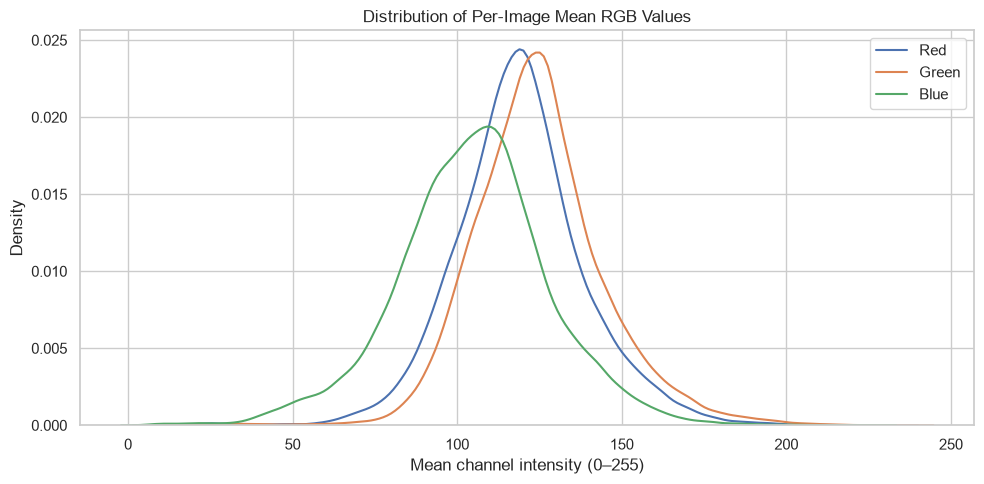

In [22]:
rgb_columns = ["mean_red", "mean_green", "mean_blue"]

plt.figure(figsize=(10, 5))
for column in rgb_columns:
    sns.kdeplot(
        data=valid_quality_df,
        x=column,
        label=column.replace("mean_", "").title()
    )
plt.title("Distribution of Per-Image Mean RGB Values")
plt.xlabel("Mean channel intensity (0–255)")
plt.legend()
plt.tight_layout()
plt.show()

### 7.2 Mean RGB Values by Class

,mean_red,mean_green,mean_blue
class,,,
Apple___Apple_scab,103.54,114.37,106.17
Apple___Black_rot,118.78,125.72,113.70
Apple___Cedar_apple_rust,118.34,124.82,101.15
Apple___healthy,109.55,116.64,116.35
Blueberry___healthy,140.55,145.39,136.08
Cherry_(including_sour)___Powdery_mildew,116.12,123.18,103.71
Cherry_(including_sour)___healthy,138.31,144.49,121.17
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,117.38,123.28,97.79
Corn_(maize)___Common_rust_,89.14,97.03,69.35


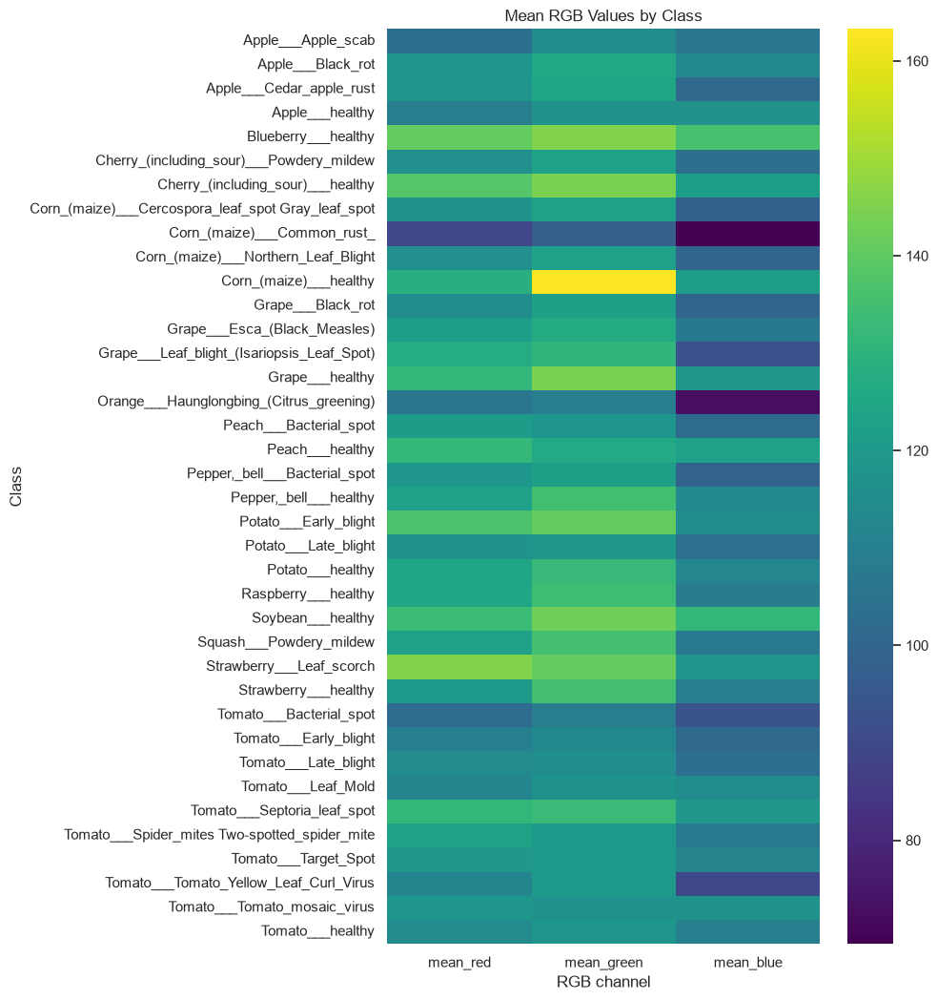

In [23]:
class_color_summary = (
    valid_quality_df.groupby("class")[rgb_columns]
    .mean()
    .sort_index()
)

display(class_color_summary.round(2))

plt.figure(figsize=(10, max(6, len(class_color_summary) * 0.28)))
sns.heatmap(class_color_summary, cmap="viridis", annot=False)
plt.title("Mean RGB Values by Class")
plt.xlabel("RGB channel")
plt.ylabel("Class")
plt.tight_layout()
plt.show()

## 8. Visual Exploration
### Objective
### 8.1 Random Samples

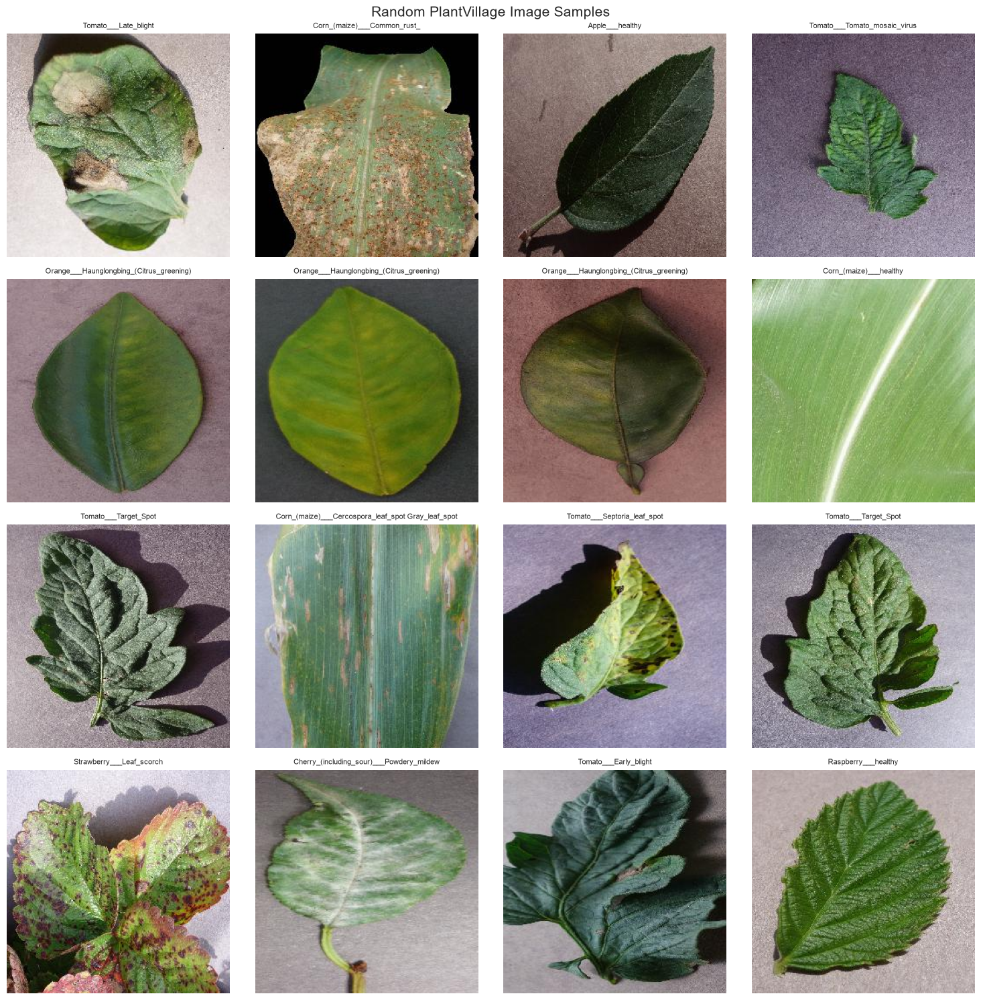

In [24]:
rng = random.Random(RANDOM_STATE)

sample_size = min(16, len(valid_df))
sample_paths = rng.sample(valid_df["path"].tolist(), sample_size)

ncols = 4
nrows = int(np.ceil(sample_size / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.8 * nrows))
axes = np.array(axes).reshape(-1)

for ax, path_string in zip(axes, sample_paths):
    with Image.open(path_string) as source:
        ax.imshow(ImageOps.exif_transpose(source).convert("RGB"))
    ax.set_title(get_class_name(path_string), fontsize=8)
    ax.axis("off")

for ax in axes[sample_size:]:
    ax.axis("off")

plt.suptitle("Random PlantVillage Image Samples", fontsize=15)
plt.tight_layout()
plt.show()

### 8.2 Samples Within Selected Classes

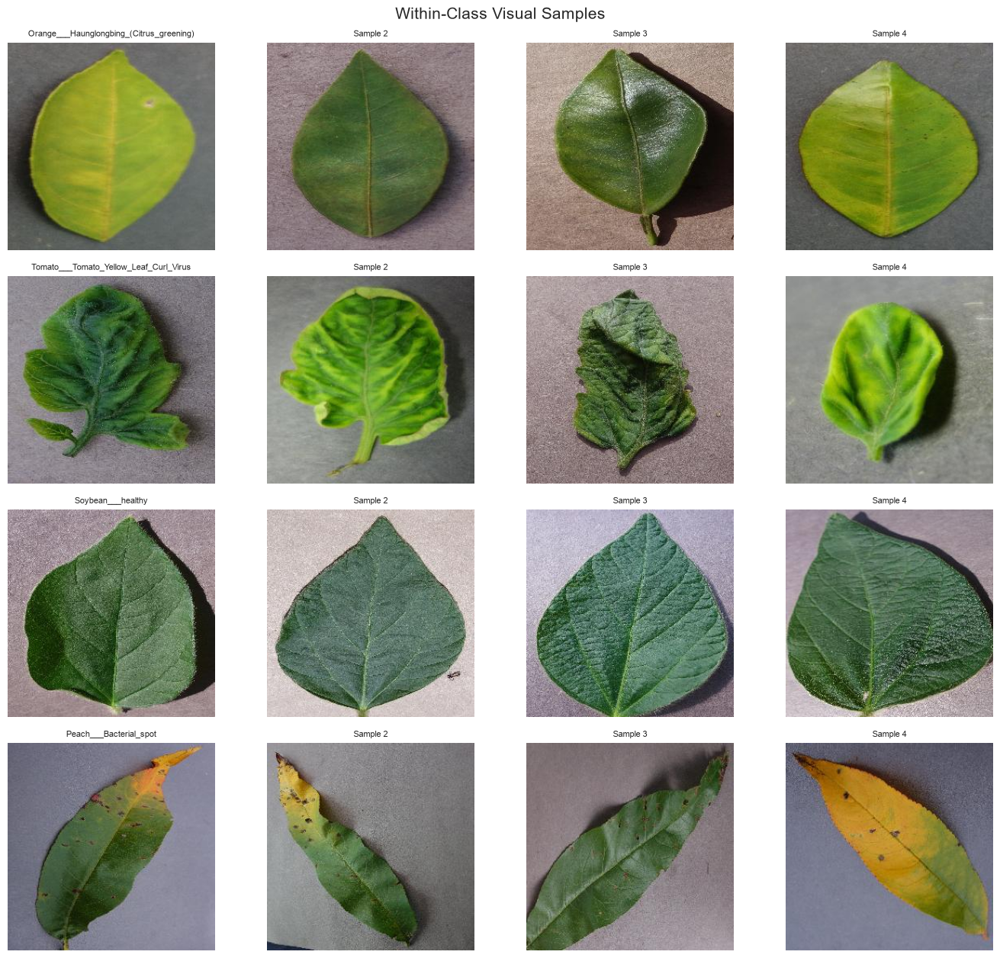

In [25]:
selected_classes = class_distribution_df["class"].head(4).tolist()

fig, axes = plt.subplots(
    len(selected_classes), 4, figsize=(14, 3.2 * len(selected_classes))
)
axes = np.array(axes).reshape(len(selected_classes), 4)

for row, class_name in enumerate(selected_classes):
    class_paths = valid_df.loc[valid_df["class"] == class_name, "path"].tolist()
    chosen = rng.sample(class_paths, min(4, len(class_paths)))

    for col in range(4):
        ax = axes[row, col]
        if col < len(chosen):
            with Image.open(chosen[col]) as source:
                ax.imshow(ImageOps.exif_transpose(source).convert("RGB"))
            ax.set_title(class_name if col == 0 else f"Sample {col + 1}", fontsize=8)
        ax.axis("off")

plt.suptitle("Within-Class Visual Samples", fontsize=15)
plt.tight_layout()
plt.show()

## 9. Image Quality Audit
### Objective
### 9.1 Overall Quality Statistics

In [26]:
metric_columns = [
    "brightness",
    "contrast",
    "dark_pixel_pct",
    "bright_pixel_pct",
    "mean_saturation",
    "sharpness_laplacian_var",
]

display(
    valid_quality_df[metric_columns]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T.round(3)
)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
brightness,54305.0,120.703,19.509,8.246,77.051,92.107,108.755,119.878,130.888,154.927,173.902,235.059
contrast,54305.0,40.170,11.593,7.456,16.651,21.431,31.447,40.506,48.516,58.533,68.073,93.371
dark_pixel_pct,54305.0,1.075,5.996,0.000,0.000,0.000,0.000,0.021,0.182,1.741,35.218,91.263
bright_pixel_pct,54305.0,0.118,1.167,0.000,0.000,0.000,0.000,0.002,0.034,0.299,2.008,71.635
mean_saturation,54305.0,68.602,21.490,12.228,30.972,38.420,52.623,65.990,81.376,109.353,126.068,230.456
sharpness_laplacian_var,54305.0,3828.493,3590.651,4.439,35.189,79.848,910.135,3068.577,5806.412,10037.016,17130.103,27301.064


### 9.2 Quality Metric Distributions

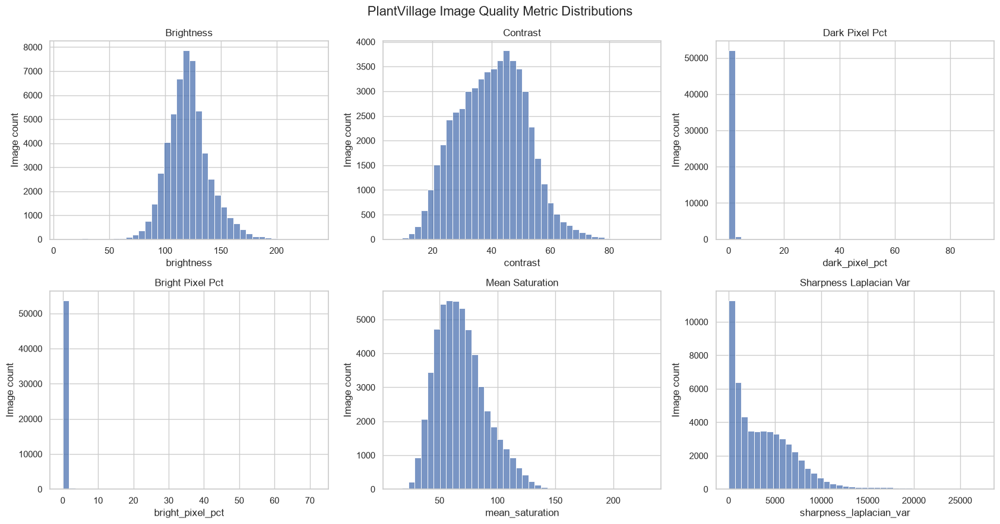

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, column in zip(axes.flat, metric_columns):
    sns.histplot(data=valid_quality_df, x=column, bins=40, ax=ax)
    ax.set_title(column.replace("_", " ").title())
    ax.set_ylabel("Image count")

plt.suptitle("PlantVillage Image Quality Metric Distributions", fontsize=16)
plt.tight_layout()
plt.show()

### 9.3 Class-Level Quality Comparison

In [28]:
class_quality_summary = (
    valid_quality_df
    .groupby("class")
    .agg(
        image_count=("path", "count"),
        mean_brightness=("brightness", "mean"),
        median_brightness=("brightness", "median"),
        mean_contrast=("contrast", "mean"),
        mean_saturation=("mean_saturation", "mean"),
        median_sharpness=("sharpness_laplacian_var", "median"),
        mean_dark_pixel_pct=("dark_pixel_pct", "mean"),
        mean_bright_pixel_pct=("bright_pixel_pct", "mean"),
    )
    .sort_values("image_count", ascending=False)
)

display(class_quality_summary.round(3))

,image_count,mean_brightness,median_brightness,mean_contrast,mean_saturation,median_sharpness,mean_dark_pixel_pct,mean_bright_pixel_pct
class,,,,,,,,
Orange___Haunglongbing_(Citrus_greening),5507,103.864,103.526,30.969,101.045,385.856,0.022,0.012
Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357,114.198,113.434,34.714,76.665,363.210,0.116,0.003
Soybean___healthy,5090,138.480,138.102,47.308,47.871,5373.416,0.051,0.221
Peach___Bacterial_spot,2297,117.539,117.645,32.992,65.651,1115.079,0.147,0.008
Tomato___Bacterial_spot,2127,104.916,102.962,33.415,56.956,986.316,0.012,0.000
Tomato___Late_blight,1909,113.427,118.495,39.590,54.958,1617.803,6.023,0.057
Squash___Powdery_mildew,1835,128.301,125.221,29.082,66.475,4972.688,0.015,0.029
Tomato___Septoria_leaf_spot,1771,130.901,127.950,37.840,65.626,4746.503,0.460,0.052
Tomato___Spider_mites Two-spotted_spider_mite,1676,119.272,120.132,44.563,59.383,6947.427,0.164,0.015


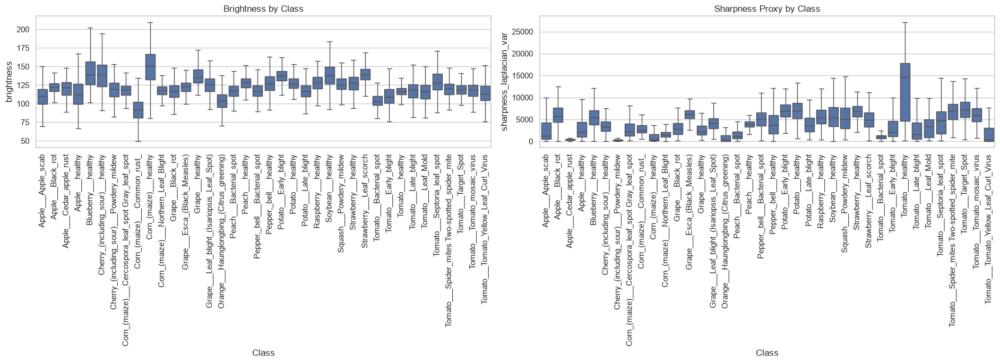

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(19, 7))

sns.boxplot(data=valid_quality_df, x="class", y="brightness",
            ax=axes[0], showfliers=False)
axes[0].set_title("Brightness by Class")
axes[0].tick_params(axis="x", rotation=90)
axes[0].set_xlabel("Class")

sns.boxplot(data=valid_quality_df, x="class", y="sharpness_laplacian_var",
            ax=axes[1], showfliers=False)
axes[1].set_title("Sharpness Proxy by Class")
axes[1].tick_params(axis="x", rotation=90)
axes[1].set_xlabel("Class")

plt.tight_layout()
plt.show()

### 9.4 Screening Rules for Potential Quality Issues
- **Very low brightness:** mean brightness below 50.
- **Very low contrast:** grayscale standard deviation below 20.
- **Potential blur:** sharpness proxy at or below the 5th percentile of the valid dataset.
- **Potential clipping:** at least 20% of pixels are extremely dark or extremely bright.

In [30]:
LOW_BRIGHTNESS_THRESHOLD = 50
LOW_CONTRAST_THRESHOLD = 20
SHARPNESS_REVIEW_PERCENTILE = 0.05
CLIPPING_PERCENT_THRESHOLD = 20

sharpness_threshold = valid_quality_df["sharpness_laplacian_var"].quantile(
    SHARPNESS_REVIEW_PERCENTILE
)

valid_quality_df["flag_low_brightness"] = (
    valid_quality_df["brightness"] < LOW_BRIGHTNESS_THRESHOLD
)
valid_quality_df["flag_low_contrast"] = (
    valid_quality_df["contrast"] < LOW_CONTRAST_THRESHOLD
)
valid_quality_df["flag_low_sharpness"] = (
    valid_quality_df["sharpness_laplacian_var"] <= sharpness_threshold
)
valid_quality_df["flag_extreme_clipping"] = (
    (valid_quality_df["dark_pixel_pct"] >= CLIPPING_PERCENT_THRESHOLD)
    | (valid_quality_df["bright_pixel_pct"] >= CLIPPING_PERCENT_THRESHOLD)
)

flag_columns = [
    "flag_low_brightness",
    "flag_low_contrast",
    "flag_low_sharpness",
    "flag_extreme_clipping",
]

valid_quality_df["quality_flag_count"] = valid_quality_df[flag_columns].sum(axis=1)
valid_quality_df["needs_visual_review"] = valid_quality_df["quality_flag_count"] > 0

quality_review_df = valid_quality_df[valid_quality_df["needs_visual_review"]].copy()

flag_summary = pd.DataFrame({
    "Review reason": [
        "Low brightness",
        "Low contrast",
        "Low sharpness proxy",
        "Extreme dark/bright pixel clipping",
        "Any quality flag (unique images)",
    ],
    "Image count": [
        int(valid_quality_df["flag_low_brightness"].sum()),
        int(valid_quality_df["flag_low_contrast"].sum()),
        int(valid_quality_df["flag_low_sharpness"].sum()),
        int(valid_quality_df["flag_extreme_clipping"].sum()),
        int(valid_quality_df["needs_visual_review"].sum()),
    ],
})

print("QUALITY REVIEW SUMMARY")
print("=" * 45)
print("Low-sharpness threshold (5th percentile):", round(sharpness_threshold, 3))
print("Images are flagged only; no files have been removed.")
display(flag_summary)

print("\nTop 30 flagged images (most flags first, then lowest sharpness):")
display(
    quality_review_df[
        ["class", "filename", "brightness", "contrast",
         "sharpness_laplacian_var", "dark_pixel_pct",
         "bright_pixel_pct", "quality_flag_count", "path"]
    ]
    .sort_values(["quality_flag_count", "sharpness_laplacian_var"],
                 ascending=[False, True])
    .head(30)
)

QUALITY REVIEW SUMMARY
Low-sharpness threshold (5th percentile): 79.848
Images are flagged only; no files have been removed.


,Review reason,Image count
0,Low brightness,151
1,Low contrast,1808
2,Low sharpness proxy,2716
3,Extreme dark/bright pixel clipping,1173
4,Any quality flag (unique images),4933



Top 30 flagged images (most flags first, then lowest sharpness):


,class,filename,brightness,contrast,sharpness_laplacian_var,dark_pixel_pct,bright_pixel_pct,quality_flag_count,path
8862,Corn_(maize)___healthy,7bedea19-5d9f-4bee-a1a1-091a168d4672___R.S_HL ...,163.982147,15.973128,4.438885,0.0,0.007629,2,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
53249,Tomato___Tomato_Yellow_Leaf_Curl_Virus,cd37cbce-e141-40a5-8af6-8fa6790c7ed3___UF.GRC_...,112.304276,17.532431,5.033697,0.0,0.000000,2,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
52448,Tomato___Tomato_Yellow_Leaf_Curl_Virus,a5b5d284-5081-4340-9cfa-be58ed74aea3___UF.GRC_...,122.512619,17.522522,5.205840,0.0,0.000000,2,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
8451,Corn_(maize)___healthy,205f8753-7598-4469-86c2-59307f90e85c___R.S_HL ...,177.452499,19.769432,7.657609,0.0,1.225281,2,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
53106,Tomato___Tomato_Yellow_Leaf_Curl_Virus,c6380761-954b-4a14-b686-05ce51868611___UF.GRC_...,132.973358,18.371521,9.230139,0.0,0.000000,2,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
53016,Tomato___Tomato_Yellow_Leaf_Curl_Virus,c1608c9f-8ae7-444b-afa5-bc50051e2d1a___UF.GRC_...,133.797684,16.218050,9.881795,0.0,0.000000,2,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
49167,Tomato___Tomato_Yellow_Leaf_Curl_Virus,0a9ce4eb-961b-4f11-a06f-2946cfd0d562___UF.GRC_...,125.182098,12.642920,10.171833,0.0,0.000000,2,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
9089,Corn_(maize)___healthy,adda5157-0c8f-4077-b89f-8be51e8cb9d8___R.S_HL ...,137.478363,15.650664,10.443408,0.0,0.000000,2,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
50341,Tomato___Tomato_Yellow_Leaf_Curl_Virus,41b73fb7-4f01-4519-8876-afb3c716fbe1___UF.GRC_...,134.762222,19.053867,10.521080,0.0,0.000000,2,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
9321,Corn_(maize)___healthy,e30f6f58-1ca0-44a0-bfd6-e3472122a5c7___R.S_HL ...,136.530823,14.135475,11.887532,0.0,0.000000,2,C:\Users\omarw\Downloads\PlantVillage-Dataset-...


### 9.5 Visual Review of Flagged Images

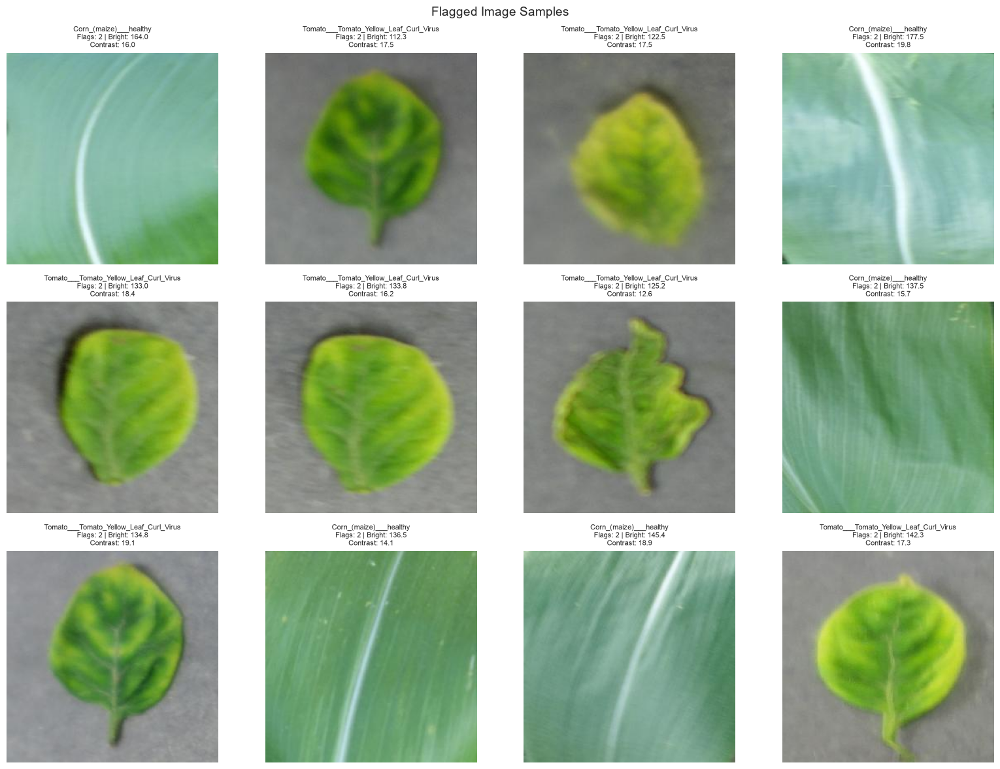

In [31]:
def display_quality_samples(dataframe, n=12, title="Flagged Image Samples"):
    if dataframe.empty:
        print("No images were flagged by the selected rules.")
        return

    sample = dataframe.head(n)
    ncols = 4
    nrows = int(np.ceil(len(sample) / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, (_, row) in zip(axes, sample.iterrows()):
        with Image.open(row["path"]) as img:
            ax.imshow(ImageOps.exif_transpose(img).convert("RGB"))
        ax.set_title(
            f'{row["class"]}\n'
            f'Flags: {row["quality_flag_count"]} | Bright: {row["brightness"]:.1f}\n'
            f'Contrast: {row["contrast"]:.1f}',
            fontsize=8
        )
        ax.axis("off")

    for ax in axes[len(sample):]:
        ax.axis("off")

    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


display_quality_samples(
    quality_review_df.sort_values(
        ["quality_flag_count", "sharpness_laplacian_var"],
        ascending=[False, True]
    ),
    n=12
)

### 9.6 Visual Inspection Findings
- Images generally contain recognizable plant leaves.
- Brightness and lighting conditions vary.
- Some images have low brightness or low contrast.
- Backgrounds vary, including black, gray, and natural backgrounds.
- Some images show visible disease symptoms, discoloration, and leaf damage.
- No image is removed automatically because of brightness, contrast, sharpness, or clipping measurements alone.

## 10. Duplicate and Near-Duplicate Detection
### Objective
### 10.1 Exact Duplicates (SHA-256)

In [32]:
def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


hash_df = valid_df[["path", "relative_path", "class", "filename"]].copy()
hash_df["sha256"] = [
    sha256_file(p) for p in tqdm(hash_df["path"], desc="Hashing images")
]

# Files that share a hash with at least one other file
duplicate_files = hash_df[hash_df.duplicated("sha256", keep=False)].copy()

group_info = duplicate_files.groupby("sha256").agg(
    group_file_count=("path", "count"),
    n_classes=("class", "nunique"),
    group_classes=("class", lambda s: " | ".join(sorted(s.unique()))),
)

duplicates_df = duplicate_files.merge(group_info, on="sha256")
duplicates_df["duplicate_type"] = np.where(
    duplicates_df["n_classes"] == 1, "same_class", "cross_class"
)
duplicates_df["duplicate_group"] = (
    duplicates_df.groupby("sha256", sort=True).ngroup() + 1
)
duplicates_df = duplicates_df.sort_values(
    ["duplicate_group", "relative_path"]
).reset_index(drop=True)

duplicate_group_count = duplicates_df["duplicate_group"].nunique()

print("EXACT DUPLICATE ANALYSIS")
print("=" * 50)
print("Images hashed:", len(hash_df))
print("Duplicate groups:", duplicate_group_count)
print("Images involved in duplicates:", len(duplicates_df))
print("Extra duplicate copies:", len(duplicates_df) - duplicate_group_count)
print("Same-class duplicate groups:",
      duplicates_df.loc[duplicates_df["duplicate_type"] == "same_class",
                        "duplicate_group"].nunique())
print("Cross-class duplicate groups:",
      duplicates_df.loc[duplicates_df["duplicate_type"] == "cross_class",
                        "duplicate_group"].nunique())

display(duplicates_df.head(20))

Hashing images: 100%|██████████| 54305/54305 [00:35<00:00, 1542.87it/s]


EXACT DUPLICATE ANALYSIS
Images hashed: 54305
Duplicate groups: 21
Images involved in duplicates: 42
Extra duplicate copies: 21
Same-class duplicate groups: 21
Cross-class duplicate groups: 0


,path,relative_path,class,filename,sha256,group_file_count,n_classes,group_classes,duplicate_type,duplicate_group
0,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Tomato___healthy\488feb1c-4b9f-44e7-8aa6-4103a...,Tomato___healthy,488feb1c-4b9f-44e7-8aa6-4103a9601f5f___GH_HL L...,12852b3616bcf0ba39b03b5677e74f50f5f6abf4d38957...,2,1,Tomato___healthy,same_class,1
1,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Tomato___healthy\a5de43e7-fc2f-4a14-a8e6-c0f2f...,Tomato___healthy,a5de43e7-fc2f-4a14-a8e6-c0f2f94c84f1___GH_HL L...,12852b3616bcf0ba39b03b5677e74f50f5f6abf4d38957...,2,1,Tomato___healthy,same_class,1
2,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Apple___healthy\f2cda910-55c7-46d7-b1a2-9a3bb9...,Apple___healthy,f2cda910-55c7-46d7-b1a2-9a3bb9792148___RS_HL 6...,262198126fd6d982126b69261723e13abb36b383138797...,2,1,Apple___healthy,same_class,2
3,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Apple___healthy\fdbfa6f7-f887-442d-8df1-1f0cf8...,Apple___healthy,fdbfa6f7-f887-442d-8df1-1f0cf839fc4d___RS_HL 6...,262198126fd6d982126b69261723e13abb36b383138797...,2,1,Apple___healthy,same_class,2
4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Tomato___healthy\068e324c-faf6-40d6-8f83-57890...,Tomato___healthy,068e324c-faf6-40d6-8f83-578907f1cac5___GH_HL L...,2a05a74db3a270ac0ec77c00ebe89a332eed5898194351...,2,1,Tomato___healthy,same_class,3
5,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Tomato___healthy\34c81c57-e1fa-49dd-a49d-34fe8...,Tomato___healthy,34c81c57-e1fa-49dd-a49d-34fe8b2385fe___GH_HL L...,2a05a74db3a270ac0ec77c00ebe89a332eed5898194351...,2,1,Tomato___healthy,same_class,3
6,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Tomato___Late_blight\5f21282c-e2ef-4c4a-ace1-b...,Tomato___Late_blight,5f21282c-e2ef-4c4a-ace1-b5701fe7effc___GHLB2 L...,2aeb7479e975df37dfb54aa7b403f57f2ad90b018c3780...,2,1,Tomato___Late_blight,same_class,4
7,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Tomato___Late_blight\e5d707cd-077c-43af-bda9-6...,Tomato___Late_blight,e5d707cd-077c-43af-bda9-6138e516ff51___GHLB2 L...,2aeb7479e975df37dfb54aa7b403f57f2ad90b018c3780...,2,1,Tomato___Late_blight,same_class,4
8,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Tomato___healthy\9662364c-aaba-45e3-b907-10792...,Tomato___healthy,9662364c-aaba-45e3-b907-10792d60578c___GH_HL L...,32e9ffabaa054c19ae8df95e94fbd7a25105defdea1214...,2,1,Tomato___healthy,same_class,5
9,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Tomato___healthy\d2ce7896-6fa4-45e6-96c5-d162d...,Tomato___healthy,d2ce7896-6fa4-45e6-96c5-d162da0e3e1c___GH_HL L...,32e9ffabaa054c19ae8df95e94fbd7a25105defdea1214...,2,1,Tomato___healthy,same_class,5


### 10.2 Cross-Class Exact Duplicates

In [33]:
cross_class_duplicates = duplicates_df[
    duplicates_df["duplicate_type"] == "cross_class"
].copy()

print("Cross-class exact-duplicate groups:",
      cross_class_duplicates["duplicate_group"].nunique())
display(cross_class_duplicates)

Cross-class exact-duplicate groups: 0


,path,relative_path,class,filename,sha256,group_file_count,n_classes,group_classes,duplicate_type,duplicate_group


### 10.3 Perceptual Hashes (pHash)

In [34]:
phash_records = []

for path_string, class_name, filename in tqdm(
    zip(valid_df["path"], valid_df["class"], valid_df["filename"]),
    total=len(valid_df),
    desc="Computing pHash"
):
    try:
        with Image.open(path_string) as img:
            img_hash = imagehash.phash(img)
        phash_records.append({
            "class": class_name,
            "filename": filename,
            "path": path_string,
            "phash": int(str(img_hash), 16),
        })
    except Exception as exc:
        print(f"Error processing {filename}: {exc}")

phash_df = pd.DataFrame(phash_records)

print("PERCEPTUAL HASH SUMMARY")
print("=" * 50)
print("Images processed:", len(phash_df))
print("Unique perceptual hashes:", phash_df["phash"].nunique())

Computing pHash: 100%|██████████| 54305/54305 [00:49<00:00, 1089.90it/s]

PERCEPTUAL HASH SUMMARY
Images processed: 54305
Unique perceptual hashes: 54283


### 10.4 Near-Duplicate Search with a BK-Tree

In [35]:
HAMMING_THRESHOLD = 4


def hamming_distance(hash1, hash2):
    # Hamming distance between two 64-bit hashes
    return (hash1 ^ hash2).bit_count()


class BKTree:

    def __init__(self):
        self.root = None

    def add(self, value, index):
        if self.root is None:
            self.root = {"value": value, "indices": [index], "children": {}}
            return

        node = self.root
        while True:
            distance = hamming_distance(value, node["value"])

            if distance == 0:
                node["indices"].append(index)
                return

            if distance not in node["children"]:
                node["children"][distance] = {
                    "value": value, "indices": [index], "children": {}
                }
                return

            node = node["children"][distance]

    def search(self, value, threshold):
        if self.root is None:
            return []

        results = []
        stack = [self.root]

        while stack:
            node = stack.pop()
            distance = hamming_distance(value, node["value"])

            if distance <= threshold:
                results.extend([(idx, distance) for idx in node["indices"]])

            lower = distance - threshold
            upper = distance + threshold

            for edge, child in node["children"].items():
                if lower <= edge <= upper:
                    stack.append(child)

        return results


sha_lookup = dict(zip(hash_df["path"], hash_df["sha256"]))

tree = BKTree()
near_duplicate_pairs = []

for index, row in phash_df.iterrows():
    matches = tree.search(row["phash"], HAMMING_THRESHOLD)

    for previous_index, distance in matches:
        previous_row = phash_df.loc[previous_index]

        # Skip byte-identical files (already handled as exact duplicates)
        if sha_lookup.get(row["path"]) == sha_lookup.get(previous_row["path"]):
            continue

        near_duplicate_pairs.append({
            "class_1": previous_row["class"],
            "filename_1": previous_row["filename"],
            "class_2": row["class"],
            "filename_2": row["filename"],
            "hamming_distance": distance,
            "path_1": previous_row["path"],
            "path_2": row["path"],
        })

    tree.add(row["phash"], index)

near_duplicates_df = pd.DataFrame(
    near_duplicate_pairs,
    columns=["class_1", "filename_1", "class_2", "filename_2",
             "hamming_distance", "path_1", "path_2"]
)

near_duplicate_image_paths = (
    set(near_duplicates_df["path_1"]) | set(near_duplicates_df["path_2"])
)

print("NEAR-DUPLICATE ANALYSIS")
print("=" * 50)
print("Near-duplicate pairs:", len(near_duplicates_df))
print("Unique images involved:", len(near_duplicate_image_paths))

if near_duplicates_df.empty:
    print("No near-duplicate pairs detected.")
else:
    print("\nHamming distance distribution:")
    display(near_duplicates_df["hamming_distance"].value_counts().sort_index())
    print("\nDetected near-duplicate pairs (first 20):")
    display(near_duplicates_df.head(20))

NEAR-DUPLICATE ANALYSIS
Near-duplicate pairs: 1444
Unique images involved: 1698

Hamming distance distribution:


hamming_distance
0       1
2      96
4    1347
Name: count, dtype: int64


Detected near-duplicate pairs (first 20):


,class_1,filename_1,class_2,filename_2,hamming_distance,path_1,path_2
0,Apple___Black_rot,6af96fb3-002f-48b3-a2e8-fb5cf30dfa63___JR_FrgE...,Apple___Black_rot,f83c1286-8bdb-48e6-ac8f-bd8a5209afc7___JR_FrgE...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
1,Apple___Black_rot,30aebb07-bde6-44c8-bee2-a06ff42a948d___JR_FrgE...,Apple___Black_rot,fb8255a6-e05d-44d3-a115-80c1e55009bd___JR_FrgE...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
2,Apple___Black_rot,4eeaca51-3ca2-4afe-884a-d65c2e31e452___JR_FrgE...,Apple___Black_rot,fc5f6bd3-bd4e-4a8c-94d1-d46ea92a3941___JR_FrgE...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
3,Apple___healthy,298c8daf-43cc-4f65-b2db-65623425e5f8___RS_HL 6...,Apple___healthy,9fc6acc1-0394-498d-b51c-d2e92febae55___RS_HL 6...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
4,Apple___healthy,375f1e44-235c-4ef0-a156-077b71abeed3___RS_HL 8...,Apple___healthy,abc9f5f6-ea98-46c0-8df7-2986969318bf___RS_HL 5...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
5,Apple___healthy,946b311a-cb67-46d4-8c8b-0d91ebd456f3___RS_HL 5...,Apple___healthy,b6808ea5-f26b-49fa-87b2-a1bbbc98d74c___RS_HL 6...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
6,Apple___Apple_scab,f6946261-1a18-4306-ba87-ca25344d9bd2___FREC_Sc...,Blueberry___healthy,23d13863-7320-427f-8559-9665257b9540___RS_HL 2...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
7,Blueberry___healthy,163fa1ca-f6b9-4ce4-8218-771750b3043f___RS_HL 5...,Blueberry___healthy,3b4ab949-7b1d-4127-a1d3-8f125989f495___RS_HL 5...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
8,Blueberry___healthy,201aef7f-4e1c-4197-ae37-66ca340909bc___RS_HL 0...,Blueberry___healthy,76610fbe-b5da-460e-ae69-29e89b02f1dd___RS_HL 0...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
9,Blueberry___healthy,39a6957f-2837-4a39-bb60-a8a3c155290f___RS_HL 5...,Blueberry___healthy,7b7ada95-0a08-4b41-a028-e4ba89ca33c4___RS_HL 5...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...


### 10.5 Cross-Class Near-Duplicates

In [36]:
cross_class_near_duplicates = near_duplicates_df[
    near_duplicates_df["class_1"] != near_duplicates_df["class_2"]
].copy()

print("Cross-class near-duplicate pairs:", len(cross_class_near_duplicates))
display(cross_class_near_duplicates.head(20))

Cross-class near-duplicate pairs: 300


,class_1,filename_1,class_2,filename_2,hamming_distance,path_1,path_2
6,Apple___Apple_scab,f6946261-1a18-4306-ba87-ca25344d9bd2___FREC_Sc...,Blueberry___healthy,23d13863-7320-427f-8559-9665257b9540___RS_HL 2...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
16,Blueberry___healthy,e35a63f4-5fa8-40af-9e59-a63b67801bcf___RS_HL 4...,Cherry_(including_sour)___healthy,0a273dc4-db45-4936-aee3-59919e1df44f___JR_HL 9...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
17,Apple___healthy,5941b857-a525-4aff-ba20-def608d63c4d___RS_HL 6...,Cherry_(including_sour)___healthy,162dc895-00e6-4f02-ab49-a7030ec8984d___JR_HL 9...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
19,Blueberry___healthy,e1bba6b4-45e5-4d1f-b58f-01ef97525cc6___RS_HL 2...,Cherry_(including_sour)___healthy,3701b877-df2b-49cd-9bb9-066dd6f2f206___JR_HL 9...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
20,Apple___healthy,51cb81e8-dd15-40cd-b4f2-5287379dfe74___RS_HL 6...,Cherry_(including_sour)___healthy,3aaba56c-080d-4a21-b2d8-8fe69189a720___JR_HL 4...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
22,Apple___healthy,b0ba7a6d-95eb-44e2-a2a5-4d9ef9b489d7___RS_HL 5...,Cherry_(including_sour)___healthy,48476597-1b5c-4d55-bd30-80059a2356bf___JR_HL 9...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
64,Grape___Black_rot,24076a50-f715-4b02-b1fc-d5b83ab06174___FAM_B.R...,Orange___Haunglongbing_(Citrus_greening),11b4a4de-c43d-48ac-a5a3-00b0875f6959___CREC_HL...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
90,Cherry_(including_sour)___Powdery_mildew,341d8850-26e0-4ac5-a560-da2be3fc4b24___FREC_Pw...,Orange___Haunglongbing_(Citrus_greening),bc070003-a6bb-4cc7-8e4b-4f5d074dd408___CREC_HL...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
119,Cherry_(including_sour)___healthy,55df59e1-73fb-4feb-8099-0b832bb3fb81___JR_HL 9...,Peach___healthy,02070622-2fd7-40d5-9470-27e513ea8a90___Rutg._H...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...
122,Orange___Haunglongbing_(Citrus_greening),0b4118d9-903b-4883-a8e2-d802d524e1d6___CREC_HL...,"Pepper,_bell___healthy",1663be64-8704-420b-8f9e-eb6265029f50___JR_HL 7...,4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,C:\Users\omarw\Downloads\PlantVillage-Dataset-...


### 10.6 Visual Check of Near-Duplicate Pairs

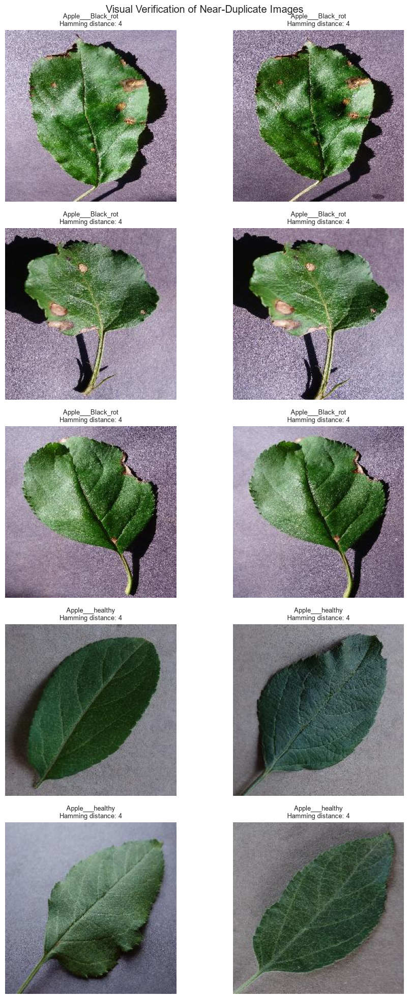

In [37]:
def inspect_duplicate_pairs(df, n=5):
    if df.empty:
        print("No pairs available for inspection.")
        return

    sample = df.head(n)
    fig, axes = plt.subplots(len(sample), 2, figsize=(10, 4 * len(sample)))
    axes = np.array(axes).reshape(len(sample), 2)

    for i, (_, row) in enumerate(sample.iterrows()):
        for col, (path_key, class_key) in enumerate(
            [("path_1", "class_1"), ("path_2", "class_2")]
        ):
            with Image.open(row[path_key]) as img:
                axes[i][col].imshow(img.convert("RGB"))
            axes[i][col].set_title(
                f"{row[class_key]}\nHamming distance: {row['hamming_distance']}",
                fontsize=9
            )
            axes[i][col].axis("off")

    plt.suptitle("Visual Verification of Near-Duplicate Images")
    plt.tight_layout()
    plt.show()


inspect_duplicate_pairs(near_duplicates_df, n=5)

## 11. Data Cleaning Decisions
### Objective
### Rules
- **Unreadable files:** excluded from the usable inventory and reported for inspection.
- **Same-class exact duplicates:** keep one copy (first by relative path); mark the remaining copies as redundant and exclude them.
- **Cross-class exact duplicates:** keep all copies but flag them for manual label review.
- **Quality flags** (Section 8) and **near-duplicate candidates** (Section 9.4)
### 11.1 Apply the Rules

In [38]:
cleaning_df = validation_df.merge(hash_df[["path", "sha256"]], on="path", how="left")
cleaning_df["cleaning_status"] = "keep"
cleaning_df["cleaning_reason"] = "Readable image; no exact duplicate detected"

# Unreadable files
invalid_mask = cleaning_df["status"] == "invalid"
cleaning_df.loc[invalid_mask, "cleaning_status"] = "exclude_invalid"
cleaning_df.loc[invalid_mask, "cleaning_reason"] = "Image could not be fully decoded"

# Exact duplicates: deterministic choice, first path in each group is the representative
dup_ranked = duplicates_df.sort_values(["duplicate_group", "relative_path"]).copy()
dup_ranked["rank_in_group"] = dup_ranked.groupby("duplicate_group").cumcount()

same_class = dup_ranked[dup_ranked["duplicate_type"] == "same_class"]
retained_paths = set(same_class.loc[same_class["rank_in_group"] == 0, "path"])
redundant_paths = set(same_class.loc[same_class["rank_in_group"] > 0, "path"])
cross_class_paths = set(
    dup_ranked.loc[dup_ranked["duplicate_type"] == "cross_class", "path"]
)

mask = cleaning_df["path"].isin(retained_paths)
cleaning_df.loc[mask, "cleaning_reason"] = "Same-class exact duplicate group; one copy retained"

mask = cleaning_df["path"].isin(cross_class_paths)
cleaning_df.loc[mask, "cleaning_status"] = "review_cross_class_duplicate"
cleaning_df.loc[mask, "cleaning_reason"] = (
    "Exact duplicate appears under multiple class labels; review labels"
)

mask = cleaning_df["path"].isin(redundant_paths)
cleaning_df.loc[mask, "cleaning_status"] = "exclude_redundant_duplicate"
cleaning_df.loc[mask, "cleaning_reason"] = (
    "Redundant same-class exact duplicate; retained representative exists"
)

# Review-only flags (these never change cleaning_status)
cleaning_df["flag_quality_review"] = cleaning_df["path"].isin(
    set(quality_review_df["path"])
)
cleaning_df["flag_near_duplicate_candidate"] = cleaning_df["path"].isin(
    near_duplicate_image_paths
)

usable_statuses = ["keep", "review_cross_class_duplicate"]
clean_inventory = (
    cleaning_df[cleaning_df["cleaning_status"].isin(usable_statuses)]
    .sort_values(["class", "relative_path"])
    .reset_index(drop=True)
)

display(cleaning_df["cleaning_status"].value_counts().rename("count").to_frame())
print("Usable inventory rows:", len(clean_inventory))

,count
cleaning_status,
keep,54284
exclude_redundant_duplicate,21


Usable inventory rows: 54284


### 10.2 Class-Level Changes

,raw_count,usable_count,difference,usable_percentage
class,,,,
Orange___Haunglongbing_(Citrus_greening),5507,5507,0,10.145
Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357,5357,0,9.868
Soybean___healthy,5090,5090,0,9.377
Peach___Bacterial_spot,2297,2297,0,4.231
Tomato___Bacterial_spot,2127,2127,0,3.918
Tomato___Late_blight,1909,1901,-8,3.502
Squash___Powdery_mildew,1835,1835,0,3.380
Tomato___Septoria_leaf_spot,1771,1771,0,3.262
Tomato___Spider_mites Two-spotted_spider_mite,1676,1676,0,3.087


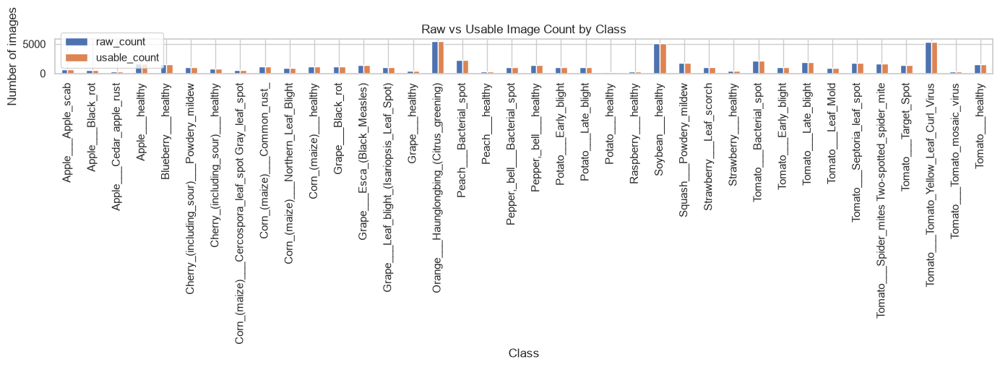

In [39]:
raw_counts = cleaning_df.groupby("class").size().rename("raw_count")
usable_counts = clean_inventory.groupby("class").size().rename("usable_count")

class_summary = pd.concat([raw_counts, usable_counts], axis=1).fillna(0).astype(int)
class_summary["difference"] = class_summary["usable_count"] - class_summary["raw_count"]
class_summary["usable_percentage"] = (
    class_summary["usable_count"] / class_summary["usable_count"].sum() * 100
).round(3)

display(class_summary.sort_values("raw_count", ascending=False))

ax = class_summary[["raw_count", "usable_count"]].plot(kind="bar", figsize=(14, 5))
ax.set_title("Raw vs Usable Image Count by Class")
ax.set_ylabel("Number of images")
ax.set_xlabel("Class")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### 10.3 Files Requiring Attention

In [40]:
print("INVALID FILES")
display(invalid_df[["relative_path", "file_size_bytes", "error"]])

print("CROSS-CLASS EXACT DUPLICATES")
display(cross_class_duplicates)

INVALID FILES


,relative_path,file_size_bytes,error


CROSS-CLASS EXACT DUPLICATES


,path,relative_path,class,filename,sha256,group_file_count,n_classes,group_classes,duplicate_type,duplicate_group


### 10.4 Cleaning Summary

In [41]:
cleaning_summary = pd.DataFrame({
    "Metric": [
        "Images in the original inventory",
        "Classes found",
        "Unreadable images excluded",
        "Same-class exact-duplicate copies excluded",
        "Cross-class exact-duplicate groups flagged",
        "Cross-class exact-duplicate records flagged",
        "Images flagged for quality review (unique, retained)",
        "Near-duplicate candidate pairs (flagged, retained)",
        "Images in near-duplicate candidates (unique, retained)",
        "Images in the usable inventory",
    ],
    "Count": [
        len(cleaning_df),
        int(cleaning_df["class"].nunique()),
        int((cleaning_df["cleaning_status"] == "exclude_invalid").sum()),
        int((cleaning_df["cleaning_status"] == "exclude_redundant_duplicate").sum()),
        int(cross_class_duplicates["duplicate_group"].nunique()),
        int((cleaning_df["cleaning_status"] == "review_cross_class_duplicate").sum()),
        int(cleaning_df["flag_quality_review"].sum()),
        len(near_duplicates_df),
        len(near_duplicate_image_paths),
        len(clean_inventory),
    ],
})

display(cleaning_summary)

# Consistency check: only invalid files and redundant same-class copies are excluded
expected_usable = (
    len(cleaning_df)
    - int((cleaning_df["cleaning_status"] == "exclude_invalid").sum())
    - int((cleaning_df["cleaning_status"] == "exclude_redundant_duplicate").sum())
)
print("Expected usable image count:", expected_usable)
print("Actual usable image count:", len(clean_inventory))
print("Count check passed:", expected_usable == len(clean_inventory))

,Metric,Count
0,Images in the original inventory,54305
1,Classes found,38
2,Unreadable images excluded,0
3,Same-class exact-duplicate copies excluded,21
4,Cross-class exact-duplicate groups flagged,0
5,Cross-class exact-duplicate records flagged,0
6,"Images flagged for quality review (unique, ret...",4933
7,"Near-duplicate candidate pairs (flagged, retai...",1444
8,"Images in near-duplicate candidates (unique, r...",1698
9,Images in the usable inventory,54284


Expected usable image count: 54284
Actual usable image count: 54284
Count check passed: True


## 12. Export and Final Summary
- `raw_inventory.csv`: every discovered image with validation, hash, decision, and review-flag fields.
- `clean_inventory.csv`: images kept for downstream work, including cross-class items flagged for review.
- `invalid_images.csv`: unreadable files.
- `exact_duplicates.csv`: all files in exact-duplicate groups.
- `class_cleaning_summary.csv`: raw and usable counts by class.
- `image_quality_metrics.csv`: per-image quality and color measurements with quality flags.
- `images_for_visual_review.csv`: images flagged by the quality rules.
- `class_quality_summary.csv`: class-level quality statistics.
- `quality_flag_summary.csv`: number of images per quality flag.

In [42]:
cleaning_df.to_csv(OUTPUT_DIR / "raw_inventory.csv", index=False)
clean_inventory.to_csv(OUTPUT_DIR / "clean_inventory.csv", index=False)
invalid_df.to_csv(OUTPUT_DIR / "invalid_images.csv", index=False)
duplicates_df.to_csv(OUTPUT_DIR / "exact_duplicates.csv", index=False)
class_summary.to_csv(OUTPUT_DIR / "class_cleaning_summary.csv")
valid_quality_df.to_csv(OUTPUT_DIR / "image_quality_metrics.csv", index=False)
quality_review_df.to_csv(OUTPUT_DIR / "images_for_visual_review.csv", index=False)
class_quality_summary.to_csv(OUTPUT_DIR / "class_quality_summary.csv")
flag_summary.to_csv(OUTPUT_DIR / "quality_flag_summary.csv", index=False)

print("Saved files:")
for path in sorted(OUTPUT_DIR.glob("*.csv")):
    print("-", path.resolve())

print("\nOriginal files modified: No")
print("Count matches expected reference count:",
      len(cleaning_df) == EXPECTED_IMAGE_COUNT)
print(
    "\nHandoff to preprocessing: load reports/clean_inventory.csv and inspect the rows "
    "marked 'review_cross_class_duplicate' (and any quality or near-duplicate flags) "
    "before model preprocessing."
)

Saved files:
- C:\Users\omarw\Downloads\reports\class_cleaning_summary.csv
- C:\Users\omarw\Downloads\reports\class_quality_summary.csv
- C:\Users\omarw\Downloads\reports\clean_inventory.csv
- C:\Users\omarw\Downloads\reports\exact_duplicates.csv
- C:\Users\omarw\Downloads\reports\image_quality_metrics.csv
- C:\Users\omarw\Downloads\reports\images_for_visual_review.csv
- C:\Users\omarw\Downloads\reports\invalid_images.csv
- C:\Users\omarw\Downloads\reports\quality_flag_summary.csv
- C:\Users\omarw\Downloads\reports\raw_inventory.csv

Original files modified: No
Count matches expected reference count: True

Handoff to preprocessing: load reports/clean_inventory.csv and inspect the rows marked 'review_cross_class_duplicate' (and any quality or near-duplicate flags) before model preprocessing.


In [43]:
# Load the already cleaned inventory and the raw inventory (to compute the expected counts)
clean_df = pd.read_csv("reports/clean_inventory.csv")
raw_df = pd.read_csv("reports/raw_inventory.csv")

# Load duplicate records for verification
duplicates_df = pd.read_csv("reports/exact_duplicates.csv")

print("Before final validation:", len(clean_df))
print("Duplicate groups:", duplicates_df["duplicate_group"].nunique())

# Expected counts come from the cleaning decisions, not from hardcoded numbers
n_original = len(raw_df)
n_dup_removed = int((raw_df["cleaning_status"] == "exclude_redundant_duplicate").sum())
n_invalid_removed = int((raw_df["cleaning_status"] == "exclude_invalid").sum())

# Verify duplicate copies are already excluded
remaining_duplicates = clean_df.duplicated(
    subset=["class", "sha256"],
    keep="first"
).sum()

print("Remaining duplicate copies:", remaining_duplicates)

# Final dataset inventory
final_df = clean_df.copy()

# Save final cleaned inventory
final_df.to_csv(
    "final_clean_inventory.csv",
    index=False
)

print("\nFINAL CLEANING RESULTS")
print("----------------------")
print("Original images:", f"{n_original:,}")
print("Duplicate copies removed:", n_dup_removed)
print("Invalid images removed:", n_invalid_removed)
print("Final images:", f"{len(final_df):,}")
print("Remaining duplicates:", remaining_duplicates)

# Verify
assert len(final_df) == n_original - n_dup_removed - n_invalid_removed
assert remaining_duplicates == 0

print("\nCleaning completed successfully!")

Before final validation: 54284
Duplicate groups: 21
Remaining duplicate copies: 0

FINAL CLEANING RESULTS
----------------------
Original images: 54,305
Duplicate copies removed: 21
Invalid images removed: 0
Final images: 54,284
Remaining duplicates: 0

Cleaning completed successfully!


# Part 1B — Dataset EDA on the Cleaned Labels (Sections E1–E8)

This EDA is about the data itself (crop, disease and class labels), not the pixels. It is computed on **`final_df`**, the cleaned dataset produced in Part 1, so every number here matches the dataset that is split and modelled in Part 2.

Nothing in this part changes `final_df`: all work happens on a copy called `eda_df`.

## E1. Build the EDA working copy from `final_df`

In [44]:
import re
import textwrap
import numpy as np
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from matplotlib.colors import LogNorm
from IPython.display import display

# `final_df` comes from the cleaning step (Section 12). Keep only the label/path columns
# so the EDA integrity checks are not affected by unrelated validation columns.
df = final_df[["path", "relative_path", "filename", "class", "extension", "file_size_bytes"]].copy()

# The class folder name has the form  Crop___Condition  (e.g. Tomato___Late_blight)
df["crop_disease"] = df["class"]
df["crop_type"]    = df["crop_disease"].str.split("___").str[0]
df["disease_name"] = df["crop_disease"].str.split("___").str[1]
df["is_healthy"]   = (df["disease_name"] == "healthy").astype(int)
df["image"]        = df["filename"]
df["text"]         = df["relative_path"]

assert df["disease_name"].notna().all(), "Some class names do not follow the Crop___Condition pattern."

print("Images:", f"{len(df):,}")
print("\nMissing values per column:")
print(df.isnull().sum())
df.head()

Images: 54,284

Missing values per column:
path               0
relative_path      0
filename           0
class              0
extension          0
file_size_bytes    0
crop_disease       0
crop_type          0
disease_name       0
is_healthy         0
image              0
text               0
dtype: int64


,path,relative_path,filename,class,extension,file_size_bytes,crop_disease,crop_type,disease_name,is_healthy,image,text
0,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Apple___Apple_scab\00075aa8-d81a-4184-8541-b69...,00075aa8-d81a-4184-8541-b692b78d398a___FREC_Sc...,Apple___Apple_scab,.jpg,9616,Apple___Apple_scab,Apple,Apple_scab,0,00075aa8-d81a-4184-8541-b692b78d398a___FREC_Sc...,Apple___Apple_scab\00075aa8-d81a-4184-8541-b69...
1,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Apple___Apple_scab\01a66316-0e98-4d3b-a56f-d78...,01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Sc...,Apple___Apple_scab,.jpg,10108,Apple___Apple_scab,Apple,Apple_scab,0,01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Sc...,Apple___Apple_scab\01a66316-0e98-4d3b-a56f-d78...
2,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Apple___Apple_scab\01f3deaa-6143-4b6c-9c22-620...,01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Sc...,Apple___Apple_scab,.jpg,12005,Apple___Apple_scab,Apple,Apple_scab,0,01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Sc...,Apple___Apple_scab\01f3deaa-6143-4b6c-9c22-620...
3,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Apple___Apple_scab\0208f4eb-45a4-4399-904e-989...,0208f4eb-45a4-4399-904e-989ac2c6257c___FREC_Sc...,Apple___Apple_scab,.jpg,19474,Apple___Apple_scab,Apple,Apple_scab,0,0208f4eb-45a4-4399-904e-989ac2c6257c___FREC_Sc...,Apple___Apple_scab\0208f4eb-45a4-4399-904e-989...
4,C:\Users\omarw\Downloads\PlantVillage-Dataset-...,Apple___Apple_scab\023123cb-7b69-4c9f-a521-766...,023123cb-7b69-4c9f-a521-766d7c8543bb___FREC_Sc...,Apple___Apple_scab,.jpg,8897,Apple___Apple_scab,Apple,Apple_scab,0,023123cb-7b69-4c9f-a521-766d7c8543bb___FREC_Sc...,Apple___Apple_scab\023123cb-7b69-4c9f-a521-766...


## E2. Basic distributions: healthy vs diseased, crops and diseases

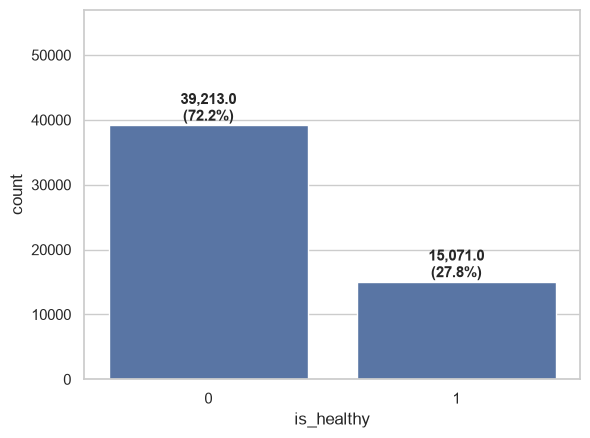

In [45]:
ax = sns.countplot(data=df, x='is_healthy')
total = len(df)
for p in ax.patches:
    height = p.get_height()
    percentage = f'{100 * height / total:.1f}%'
    ax.annotate(f'{height:,}\n({percentage})',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.ylim(0, total * 1.05)

plt.show()

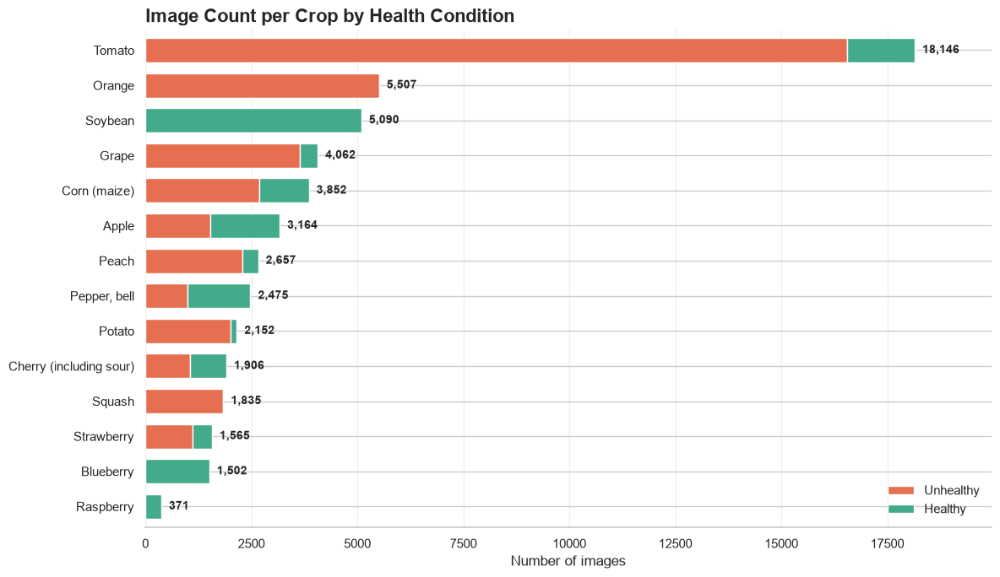

In [46]:
# Data
ct = pd.crosstab(df['crop_type'], df['is_healthy'])
ct.columns = ['Unhealthy', 'Healthy']
ct.index = ct.index.str.replace('_', ' ', regex=False)
ct = ct.loc[ct.sum(axis=1).sort_values().index]      # largest crop on top

# Chart
ax = ct.plot(kind='barh', stacked=True, figsize=(12, 7), width=0.7,
             color=['#E76F51', '#43AA8B'], edgecolor='white')

# Total at the end of each bar
for i, total in enumerate(ct.sum(axis=1)):
    ax.text(total + ct.sum(axis=1).max() * 0.01, i, f'{total:,}',
            va='center', fontsize=10, fontweight='bold')

# Clean look
ax.set_title('Image Count per Crop by Health Condition', fontsize=16, fontweight='bold', loc='left')
ax.set_xlabel('Number of images')
ax.set_ylabel('')
ax.set_xlim(0, ct.sum(axis=1).max() * 1.1)
ax.legend(title='', frameon=False, loc='lower right')
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

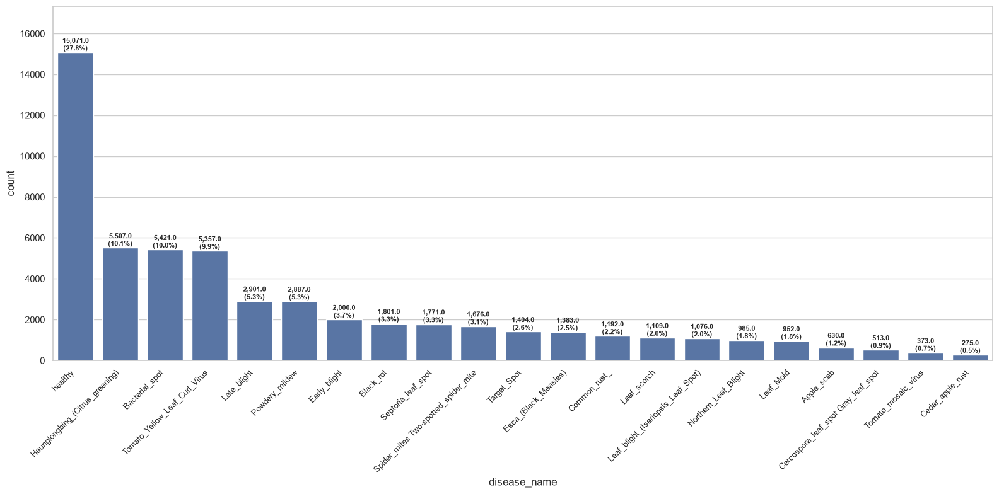

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 8))

order_dis = df['disease_name'].value_counts().index

ax = sns.countplot(data=df, x='disease_name',order=order_dis)

total = len(df)
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        percentage = f'{100 * height / total:.1f}%'
        ax.annotate(f'{height:,}\n({percentage})',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.xticks(rotation=45, ha='right', fontsize=9)
plt.ylim(0, max([p.get_height() for p in ax.patches]) * 1.15)
plt.tight_layout()
plt.show()

## E3. Working copy, helpers and dataset structure overview

In [48]:
sns.set_theme(style='whitegrid')
HEALTHY, DISEASE = '#43AA8B', '#E76F51'          # same colours as the charts above
DARK, GOLD, TEAL, SAND = '#264653', '#E9C46A', '#2A9D8F', '#F4A261'


def clean_class(s):
    crop, cond = s.split('___')
    return crop.replace('_', ' ').strip() + ' - ' + cond.replace('_', ' ').strip()


def banner(title):
    print('\n' + '=' * 72 + f'\n{title}\n' + '=' * 72)


def style_axes(ax, title, xlabel='', ylabel=''):
    ax.set_title(title, fontsize=15, fontweight='bold', loc='left')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)


# Working copy: `df` and `final_df` stay exactly as they were
eda_df = df.copy()
eda_df['crop_clean']    = eda_df['crop_type'].str.replace('_', ' ').str.strip()
eda_df['disease_clean'] = eda_df['disease_name'].str.replace('_', ' ').str.strip()
eda_df['class_clean']   = eda_df['crop_disease'].map(clean_class)
eda_df['Status']        = np.where(eda_df['is_healthy'] == 1, 'Healthy', 'Diseased')
TOTAL = len(eda_df)
assert TOTAL == len(final_df)
print(f'Working copy ready: {TOTAL:,} images')

Working copy ready: 54,284 images


In [49]:
banner('EDA  | DATASET STRUCTURE OVERVIEW')

cls_counts  = eda_df['crop_disease'].value_counts()
crop_status = (pd.crosstab(eda_df['crop_clean'], eda_df['Status'])
                 .reindex(columns=['Healthy', 'Diseased'], fill_value=0))
both      = int(((crop_status['Healthy'] > 0) & (crop_status['Diseased'] > 0)).sum())
only_h    = int(((crop_status['Healthy'] > 0) & (crop_status['Diseased'] == 0)).sum())
only_d    = int(((crop_status['Healthy'] == 0) & (crop_status['Diseased'] > 0)).sum())
n_crops   = eda_df['crop_type'].nunique()
n_classes = cls_counts.size
n_h_cls   = eda_df.loc[eda_df['is_healthy'] == 1, 'crop_disease'].nunique()
n_d_names = eda_df.loc[eda_df['is_healthy'] == 0, 'disease_name'].nunique()

overview = pd.DataFrame([
    ('Total images',                            f'{TOTAL:,}',                                       '100%'),
    ('Crop species',                            f'{n_crops}',                                       ''),
    ('Classes (crop + condition)',              f'{n_classes}',                                     ''),
    ('   - Healthy classes',                    f'{n_h_cls}',                                       f'{n_h_cls / n_classes:.1%} of classes'),
    ('   - Diseased classes',                   f'{n_classes - n_h_cls}',                           f'{(n_classes - n_h_cls) / n_classes:.1%} of classes'),
    ('Distinct disease names (excl. healthy)',  f'{n_d_names}',                                     ''),
    ('Crops with healthy AND diseased classes', f'{both}',                                          f'{both / n_crops:.1%} of crops'),
    ('Crops with a healthy class ONLY',         f'{only_h}',                                        f'{only_h / n_crops:.1%} of crops'),
    ('Crops with diseased classes ONLY',        f'{only_d}',                                        f'{only_d / n_crops:.1%} of crops'),
    ('Images per class: mean / median',         f'{cls_counts.mean():,.0f} / {cls_counts.median():,.0f}', ''),
    ('Images per class: min / max',             f'{cls_counts.min():,} / {cls_counts.max():,}',     ''),
    ('Images per class: std',                   f'{cls_counts.std():,.0f}',                         f'CV = {cls_counts.std() / cls_counts.mean():.2f}'),
], columns=['Metric', 'Value', 'Share / note'])

display(overview.style.hide(axis='index').set_properties(**{'text-align': 'left'}))
print(f'\nINSIGHT: only {both} of {n_crops} crops ({both / n_crops:.0%}) have both healthy and diseased classes; '
      f'the task is {n_classes}-class classification with {cls_counts.max() / cls_counts.min():.1f}x spread between the largest and smallest class.')


EDA  | DATASET STRUCTURE OVERVIEW


Metric,Value,Share / note
Total images,"54,284",100%
Crop species,14,
Classes (crop + condition),38,
- Healthy classes,12,31.6% of classes
- Diseased classes,26,68.4% of classes
Distinct disease names (excl. healthy),20,
Crops with healthy AND diseased classes,9,64.3% of crops
Crops with a healthy class ONLY,3,21.4% of crops
Crops with diseased classes ONLY,2,14.3% of crops
Images per class: mean / median,"1,429 / 1,092",



INSIGHT: only 9 of 14 crops (64%) have both healthy and diseased classes; the task is 38-class classification with 36.2x spread between the largest and smallest class.


## E4. Class distribution (crop + condition)


EDA | CLASS DISTRIBUTION (CROP + CONDITION)


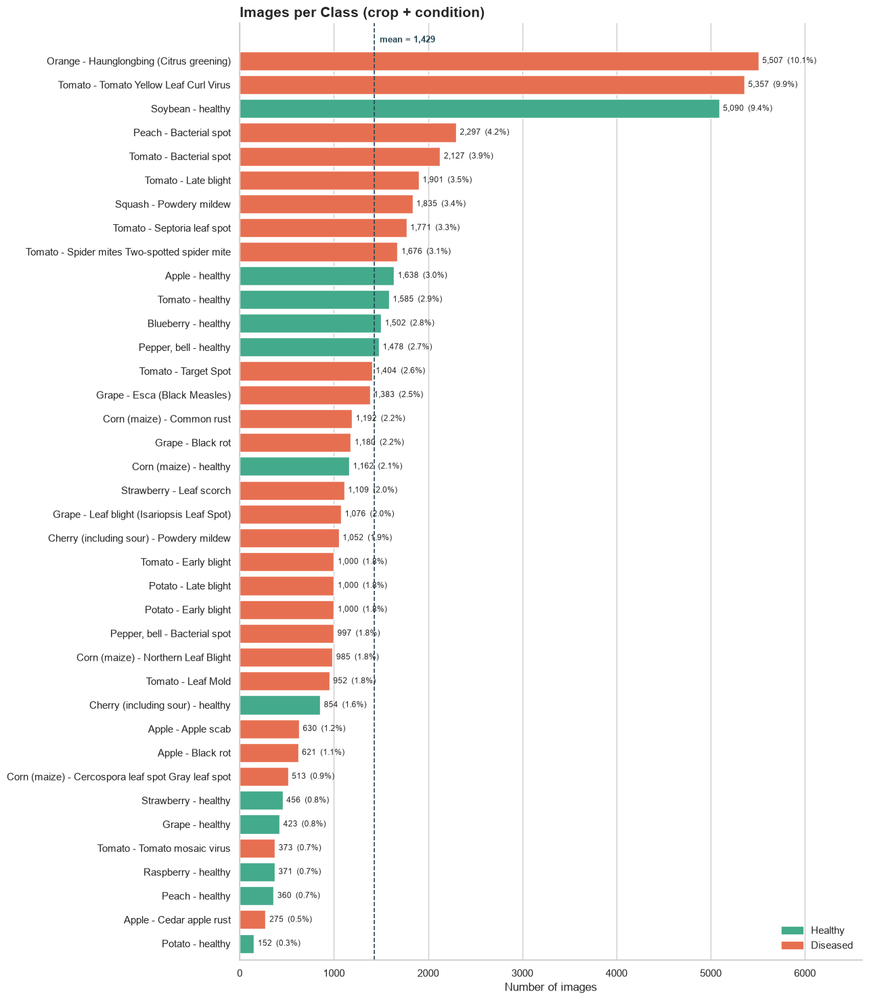

Largest class  : Orange - Haunglongbing (Citrus greening) -> 5,507 images (10.1%)
Smallest class : Potato - healthy -> 152 images (0.28%)
Top-5 classes hold 37.5% of all images; bottom-5 classes hold only 2.8%
Classes above the mean: 13 of 38  |  below 50% of the mean: 10


In [50]:
banner('EDA | CLASS DISTRIBUTION (CROP + CONDITION)')

cls_df = (eda_df.groupby(['class_clean', 'Status']).size().reset_index(name='n')
                .sort_values('n').reset_index(drop=True))
cls_df['pct'] = cls_df['n'] / TOTAL * 100
mean_n = cls_df['n'].mean()

fig, ax = plt.subplots(figsize=(13, 0.34 * len(cls_df) + 2))
bars = ax.barh(cls_df['class_clean'], cls_df['n'],
               color=cls_df['Status'].map({'Healthy': HEALTHY, 'Diseased': DISEASE}), edgecolor='white')
ax.bar_label(bars, labels=[f'{n:,}  ({p:.1f}%)' for n, p in zip(cls_df['n'], cls_df['pct'])], padding=4, fontsize=8.5)
ax.axvline(mean_n, color=DARK, ls='--', lw=1.2)
ax.text(mean_n, len(cls_df) - 0.3, f'  mean = {mean_n:,.0f}', color=DARK, fontsize=9, fontweight='bold', va='bottom')
ax.set_xlim(0, cls_df['n'].max() * 1.2)
ax.set_ylim(-0.7, len(cls_df) + 0.6)
ax.legend(handles=[Patch(color=HEALTHY, label='Healthy'), Patch(color=DISEASE, label='Diseased')], frameon=False, loc='lower right')
style_axes(ax, 'Images per Class (crop + condition)', xlabel='Number of images')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

big, small = cls_df.iloc[-1], cls_df.iloc[0]
top5, bot5 = cls_df.tail(5), cls_df.head(5)
print(f'Largest class  : {big["class_clean"]} -> {big["n"]:,} images ({big["pct"]:.1f}%)')
print(f'Smallest class : {small["class_clean"]} -> {small["n"]:,} images ({small["pct"]:.2f}%)')
print(f'Top-5 classes hold {top5["pct"].sum():.1f}% of all images; bottom-5 classes hold only {bot5["pct"].sum():.1f}%')
print(f'Classes above the mean: {(cls_df["n"] > mean_n).sum()} of {len(cls_df)}  |  '
      f'below 50% of the mean: {(cls_df["n"] < 0.5 * mean_n).sum()}')

## E5. Healthy vs diseased share inside each crop (%)


EDA | HEALTHY vs DISEASED SHARE PER CROP (%)


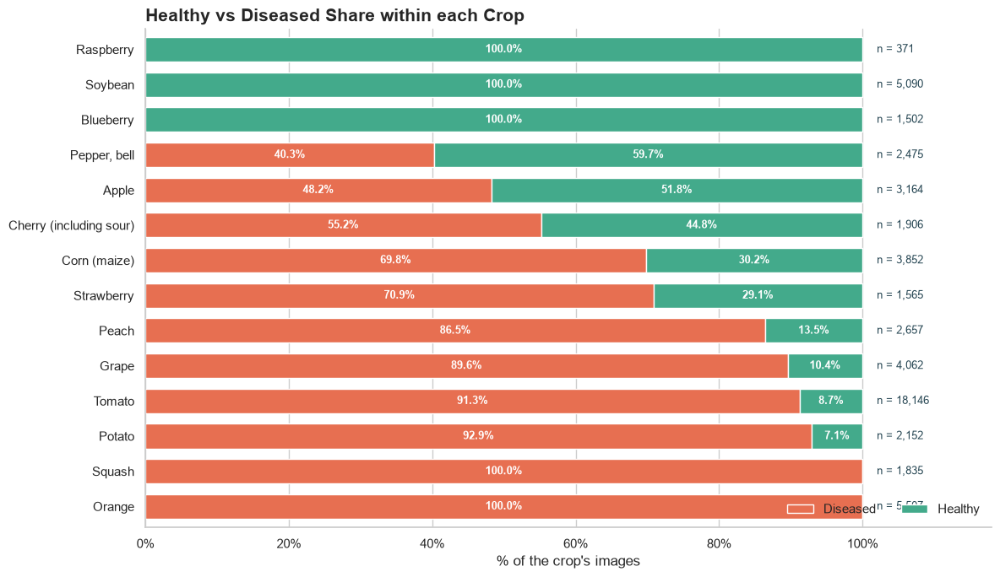

Overall: 72.2% diseased vs 27.8% healthy
Crops with NO healthy images   : Orange, Squash (13.5% of all images)
Crops with ONLY healthy images : Blueberry, Raspberry, Soybean (12.8% of all images)
Among mixed crops, most disease-heavy: Potato (92.9% diseased); most healthy-heavy: Pepper, bell (59.7% healthy)


In [51]:
banner('EDA | HEALTHY vs DISEASED SHARE PER CROP (%)')

crop_n   = (pd.crosstab(eda_df['crop_clean'], eda_df['Status'])
              .reindex(columns=['Healthy', 'Diseased'], fill_value=0))
crop_pct = (crop_n.div(crop_n.sum(axis=1), axis=0) * 100).sort_values('Healthy')

ax = crop_pct[['Diseased', 'Healthy']].plot(kind='barh', stacked=True, figsize=(12, 7), width=0.7,
                                            color=[DISEASE, HEALTHY], edgecolor='white')
for c in ax.containers:
    ax.bar_label(c, labels=[f'{v:.1f}%' if v >= 4 else '' for v in c.datavalues],
                 label_type='center', color='white', fontsize=9, fontweight='bold')
for i, crop in enumerate(crop_pct.index):
    ax.text(102, i, f'n = {crop_n.loc[crop].sum():,}', va='center', fontsize=9, color=DARK)
ax.set_xlim(0, 118)
ax.set_xticks(range(0, 101, 20))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(title='', frameon=False, loc='lower right', ncol=2)
style_axes(ax, 'Healthy vs Diseased Share within each Crop', xlabel='% of the crop\'s images')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

no_healthy   = list(crop_n.index[crop_n['Healthy'] == 0])
healthy_only = list(crop_n.index[crop_n['Diseased'] == 0])
mixed = crop_pct.drop(index=no_healthy + healthy_only)
diseased_pct = (eda_df['is_healthy'] == 0).mean() * 100

print(f'Overall: {diseased_pct:.1f}% diseased vs {100 - diseased_pct:.1f}% healthy')
print(f'Crops with NO healthy images   : {", ".join(no_healthy) or "none"} '
      f'({crop_n.loc[no_healthy].sum().sum() / TOTAL:.1%} of all images)')
print(f'Crops with ONLY healthy images : {", ".join(healthy_only) or "none"} '
      f'({crop_n.loc[healthy_only].sum().sum() / TOTAL:.1%} of all images)')
if len(mixed):
    print(f'Among mixed crops, most disease-heavy: {mixed["Diseased"].idxmax()} ({mixed["Diseased"].max():.1f}% diseased); '
          f'most healthy-heavy: {mixed["Diseased"].idxmin()} ({100 - mixed["Diseased"].min():.1f}% healthy)')

## E6. Crop x disease coverage matrix


EDA | CROP x DISEASE COVERAGE MATRIX


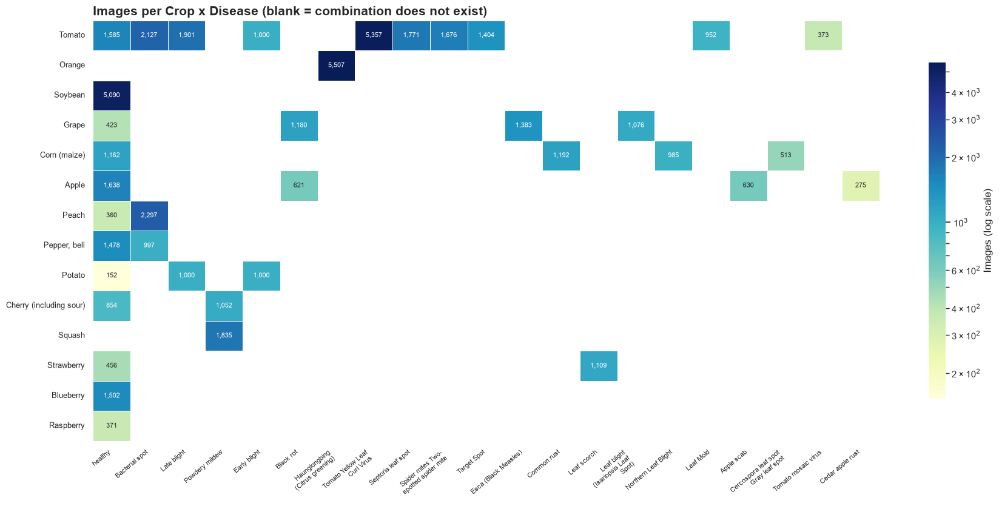

,# crops,Total images,Crops
disease_clean,,,
Bacterial spot,3,"5,421","Tomato, Peach, Pepper, bell"
Late blight,2,"2,901","Tomato, Potato"
Powdery mildew,2,"2,887","Cherry (including sour), Squash"
Early blight,2,"2,000","Tomato, Potato"
Black rot,2,"1,801","Grape, Apple"



Matrix size: 14 crops x 21 condition labels -> 87.1% of combinations are empty
5 of 20 disease names appear in more than one crop (38.3% of diseased images)
"healthy" appears in 12 of 14 crops; every other label is crop-specific or shared by at most 3 crops


In [52]:
banner('EDA | CROP x DISEASE COVERAGE MATRIX')

mat = pd.crosstab(eda_df['crop_clean'], eda_df['disease_clean'])
col_order = sorted(mat.columns, key=lambda c: (-(mat[c] > 0).sum(), -mat[c].sum()))
mat = mat.loc[mat.sum(axis=1).sort_values(ascending=False).index, col_order]

plt.figure(figsize=(18, 8.5))
ax = sns.heatmap(mat.where(mat > 0), annot=True, fmt=',.0f', cmap='YlGnBu', norm=LogNorm(),
                 linewidths=0.6, linecolor='white', annot_kws={'fontsize': 8},
                 cbar_kws={'label': 'Images (log scale)', 'shrink': 0.8})
ax.grid(False)
ax.set_xticklabels([textwrap.fill(t.get_text(), 20) for t in ax.get_xticklabels()], rotation=40, ha='right', fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_title('Images per Crop x Disease (blank = combination does not exist)', fontsize=15, fontweight='bold', loc='left')
plt.tight_layout()
plt.show()

shared = pd.DataFrame({'# crops': (mat > 0).sum(axis=0),
                       'Total images': mat.sum(axis=0),
                       'Crops': [', '.join(mat.index[mat[c] > 0]) for c in mat.columns]})
shared = shared.drop(index='healthy', errors='ignore')
shared_multi = shared[shared['# crops'] > 1].sort_values(['# crops', 'Total images'], ascending=False)
empty_cells = (mat == 0).mean().mean() * 100
d_total = int(shared['Total images'].sum())
n_shared = len(shared_multi)

display(shared_multi.style.format({'Total images': '{:,}'}))
print(f'\nMatrix size: {mat.shape[0]} crops x {mat.shape[1]} condition labels -> {empty_cells:.1f}% of combinations are empty')
print(f'{n_shared} of {len(shared)} disease names appear in more than one crop '
      f'({shared_multi["Total images"].sum() / d_total:.1%} of diseased images)')
if 'healthy' in mat.columns:
    print(f'"healthy" appears in {(mat["healthy"] > 0).sum()} of {mat.shape[0]} crops; every other label is crop-specific or shared by at most '
          f'{int(shared["# crops"].max())} crops')

## E7. Class diversity and internal imbalance per crop


EDA | CLASS DIVERSITY & INTERNAL IMBALANCE PER CROP


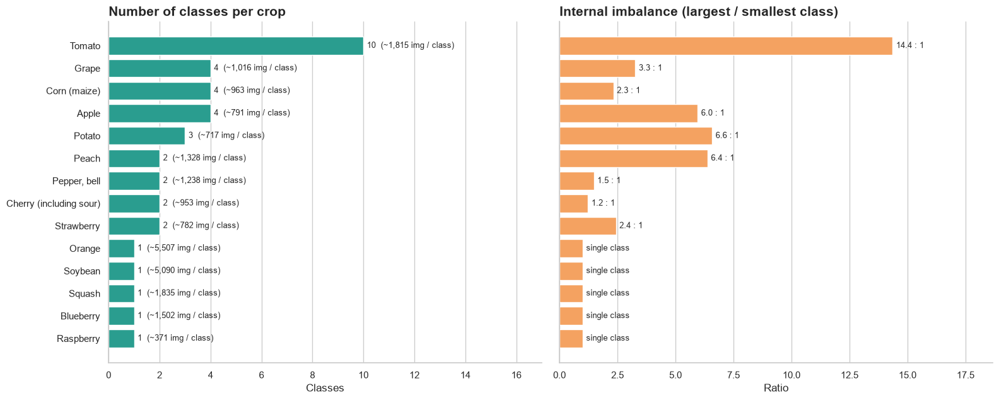

Average classes per crop : 2.7  (median 2)
Most classes             : Tomato (10 classes, 33.4% of all images)
Single-class crops       : Raspberry, Blueberry, Squash, Soybean, Orange (36% of crops)
Most uneven crop         : Tomato (14.4 : 1 between its classes)
Average internal ratio   : 4.9 : 1 across multi-class crops


In [53]:
banner('EDA | CLASS DIVERSITY & INTERNAL IMBALANCE PER CROP')

per_crop = eda_df.groupby('crop_clean').agg(classes=('crop_disease', 'nunique'), images=('image', 'size'))
inner = eda_df.groupby(['crop_clean', 'crop_disease']).size().groupby('crop_clean').agg(['min', 'max'])
per_crop['inner_ratio']   = inner['max'] / inner['min']
per_crop['avg_per_class'] = per_crop['images'] / per_crop['classes']
per_crop = per_crop.sort_values(['classes', 'images'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharey=True)
b = axes[0].barh(per_crop.index, per_crop['classes'], color=TEAL, edgecolor='white')
axes[0].bar_label(b, labels=[f'{c}  (~{a:,.0f} img / class)' for c, a in zip(per_crop['classes'], per_crop['avg_per_class'])],
                  padding=4, fontsize=9)
axes[0].set_xlim(0, per_crop['classes'].max() * 1.7)
style_axes(axes[0], 'Number of classes per crop', xlabel='Classes')

b = axes[1].barh(per_crop.index, per_crop['inner_ratio'], color=SAND, edgecolor='white')
axes[1].bar_label(b, labels=['single class' if c == 1 else f'{r:.1f} : 1' for c, r in zip(per_crop['classes'], per_crop['inner_ratio'])],
                  padding=4, fontsize=9)
axes[1].set_xlim(0, per_crop['inner_ratio'].max() * 1.3)
style_axes(axes[1], 'Internal imbalance (largest / smallest class)', xlabel='Ratio')
for a in axes:
    a.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

single  = list(per_crop.index[per_crop['classes'] == 1])
multi   = per_crop[per_crop['classes'] > 1]
print(f'Average classes per crop : {per_crop["classes"].mean():.1f}  (median {per_crop["classes"].median():.0f})')
print(f'Most classes             : {per_crop["classes"].idxmax()} ({per_crop["classes"].max()} classes, '
      f'{per_crop["images"].loc[per_crop["classes"].idxmax()] / TOTAL:.1%} of all images)')
print(f'Single-class crops       : {", ".join(single) or "none"} ({len(single) / len(per_crop):.0%} of crops)')
if len(multi):
    print(f'Most uneven crop         : {multi["inner_ratio"].idxmax()} ({multi["inner_ratio"].max():.1f} : 1 between its classes)')
    print(f'Average internal ratio   : {multi["inner_ratio"].mean():.1f} : 1 across multi-class crops')

## E8. Key findings summary

Includes the data-integrity checks, class-imbalance metrics and the pathogen-type breakdown.

In [54]:
banner('EDA SUMMARY | KEY FINDINGS & MODELLING IMPLICATIONS')

# 1) Data-integrity checks ---------------------------------------------------
_checks = [
    ('No missing values in metadata',            int(eda_df.isnull().sum().sum()) == 0),
    ('Every path yields a crop___condition label', bool(eda_df['crop_disease'].str.contains('___').all())),
    ('No duplicate file paths',                   not eda_df['text'].duplicated().any()),
    ('No duplicate file names',                   not eda_df['image'].duplicated().any()),
    ('No exact-duplicate copies left in a class', not final_df.duplicated(subset=['class', 'sha256']).any()),
]
integrity = pd.DataFrame([(name, 'PASS' if ok else 'FAIL') for name, ok in _checks],
                         columns=['Check', 'Result'])

# 2) Class-imbalance metrics -------------------------------------------------
_counts = eda_df['crop_disease'].value_counts()
K       = len(_counts)
ratio   = _counts.max() / _counts.min()

_x      = np.sort(_counts.values.astype(float))
gini    = (2 * np.sum(np.arange(1, K + 1) * _x)) / (K * _x.sum()) - (K + 1) / K

_p           = _counts.values / _counts.sum()
norm_entropy = float(-(_p * np.log(_p)).sum() / np.log(K))

k80 = int(np.searchsorted(_counts.cumsum().values / _counts.sum(), 0.80) + 1)

_minority = _counts[_counts < 0.5 * _counts.mean()]
mino = pd.Series({'Classes': len(_minority), '% images': _minority.sum() / TOTAL * 100})

# 3) Pathogen-type breakdown (diseased images only) --------------------------
def _pathogen_type(d):
    d = d.lower()
    if 'virus' in d:                                    return 'Viral'
    if 'bacterial' in d or 'citrus greening' in d:      return 'Bacterial'
    if 'mite' in d:                                     return 'Mite (pest)'
    if 'late blight' in d:                              return 'Oomycete'
    return 'Fungal'

_dis = eda_df.loc[eda_df['is_healthy'] == 0]
diseased_only = (_dis['disease_clean'].map(_pathogen_type)
                    .value_counts().rename('Images').to_frame())
diseased_only['% images'] = diseased_only['Images'] / TOTAL * 100
top_t = diseased_only['% images'].idxmax()

# ---------------------------------------------------------------------------
largest_crop = eda_df['crop_clean'].value_counts()
print('DATASET')
print(f'  - {TOTAL:,} colour images, {n_crops} crops, {n_classes} classes ({n_h_cls} healthy + {n_classes - n_h_cls} diseased)')
print(f'  - {diseased_pct:.1f}% of images are diseased, {100 - diseased_pct:.1f}% healthy')
print(f'  - {largest_crop.index[0]} is the largest crop with {largest_crop.iloc[0] / TOTAL:.1%} of images; '
      f'{largest_crop.index[-1]} the smallest with {largest_crop.iloc[-1] / TOTAL:.1%}')

print('\nQUALITY')
print(f'  - Integrity checks passed: {(integrity["Result"] == "PASS").sum()} of {len(integrity)}')
for _name in integrity.loc[integrity['Result'] == 'FAIL', 'Check']:
    print(f'      * FAILED: {_name}')

print('\nIMBALANCE')
print(f'  - Largest / smallest class = {ratio:.1f} : 1, Gini = {gini:.3f}, normalised entropy = {norm_entropy:.3f}')
print(f'  - {k80} of {K} classes make up 80% of the images')
print(f'  - Minority classes: {int(mino["Classes"])} classes hold only {mino["% images"]:.1f}% of images')

print('\nSTRUCTURE')
print(f'  - Crops with no healthy class: {", ".join(no_healthy) or "none"}; healthy-only crops: {", ".join(healthy_only) or "none"}')
print(f'  - {n_shared} disease names are shared across crops; {empty_cells:.0f}% of the crop x disease matrix is empty')
print(f'  - Largest diseased pathogen type: {top_t} ({diseased_only.loc[top_t, "% images"]:.1f}% of images)')

print('\nMODELLING IMPLICATIONS')
print('  1. Keep crop + condition as the label (classes), not the disease name alone.')
print('  2. Use class weights or augmentation for minority classes; report macro-F1 and per-class recall, not only accuracy.')
print('  3. Use stratified splits and remove duplicate files before splitting to avoid leakage.')
print('  4. Healthy-only and diseased-only crops limit what the model can learn about the healthy/diseased boundary per crop.')


EDA SUMMARY | KEY FINDINGS & MODELLING IMPLICATIONS
DATASET
  - 54,284 colour images, 14 crops, 38 classes (12 healthy + 26 diseased)
  - 72.2% of images are diseased, 27.8% healthy
  - Tomato is the largest crop with 33.4% of images; Raspberry the smallest with 0.7%

QUALITY
  - Integrity checks passed: 5 of 5

IMBALANCE
  - Largest / smallest class = 36.2 : 1, Gini = 0.400, normalised entropy = 0.919
  - 22 of 38 classes make up 80% of the images
  - Minority classes: 10 classes hold only 7.7% of images

STRUCTURE
  - Crops with no healthy class: Orange, Squash; healthy-only crops: Blueberry, Raspberry, Soybean
  - 5 disease names are shared across crops; 87% of the crop x disease matrix is empty
  - Largest diseased pathogen type: Fungal (33.1% of images)

MODELLING IMPLICATIONS
  1. Keep crop + condition as the label (classes), not the disease name alone.
  2. Use class weights or augmentation for minority classes; report macro-F1 and per-class recall, not only accuracy.
  3. Use 

# Part 2 — Preprocessing (Sections 13–21)
## Design principles
## Contents

## 13. Setup and Configuration

In [55]:
import importlib.metadata as md
import json
import os
import random
import sys
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from PIL import Image, ImageOps
from scipy.fft import dctn
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

# ---- Inputs (written by the cleaning notebook) ----
REPORTS_DIR = Path("reports")
CLEAN_INVENTORY_CSV = REPORTS_DIR / "clean_inventory.csv"

# ---- Outputs ----
PREP_DIR = Path("preprocessing_outputs")
PREP_DIR.mkdir(parents=True, exist_ok=True)

# ---- Model input ----
IMG_SIZE = 224                  # network input resolution
PAD_COLOR = (128, 128, 128)     # only used if an image is not square

# ---- Duplicate-group detection ----
THUMB_SIZE = 32                 # grayscale thumbnail used for hashing and verification
PHASH_MAX_DISTANCE = 6          # candidate pairs: Hamming distance <= this (out of 64 bits)
THUMB_CORR_MIN = 0.95           # verified pairs: thumbnail correlation >= this
CROSS_CLASS_GROUP_POLICY = "exclude"   # "exclude" or "keep"

# ---- Split ----
SPLIT_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}
N_FOLDS = 20                    # StratifiedGroupKFold folds; fractions are rounded to whole folds

# ---- Normalization and imbalance ----
NORMALIZATION = "imagenet"      # "imagenet" for pretrained backbones, "dataset" for training from scratch
CLASS_WEIGHT_STRATEGY = "effective"    # "inverse", "effective" or "none"  (loss weights)
USE_WEIGHTED_SAMPLER = False    # use EITHER loss weights OR a weighted sampler, not both

# ---- Loading ----
BATCH_SIZE = 64
# Notebook classes cannot be pickled by Windows worker processes, so use 0 workers there.
NUM_WORKERS = 0 if sys.platform.startswith("win") else min(8, os.cpu_count() or 1)
N_IO_THREADS = min(16, (os.cpu_count() or 4) * 2)

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

assert abs(sum(SPLIT_FRACTIONS.values()) - 1.0) < 1e-9, "SPLIT_FRACTIONS must sum to 1"
assert CROSS_CLASS_GROUP_POLICY in {"exclude", "keep"}
assert NORMALIZATION in {"imagenet", "dataset"}
assert CLASS_WEIGHT_STRATEGY in {"inverse", "effective", "none"}
if USE_WEIGHTED_SAMPLER and CLASS_WEIGHT_STRATEGY != "none":
    raise ValueError("Use either a weighted sampler or loss weights, not both (the imbalance would be corrected twice).")

print("Inventory:", CLEAN_INVENTORY_CSV.resolve())
print("Outputs  :", PREP_DIR.resolve())
print("Workers  :", NUM_WORKERS, "| I/O threads:", N_IO_THREADS)

Inventory: C:\Users\omarw\Downloads\reports\clean_inventory.csv
Outputs  : C:\Users\omarw\Downloads\preprocessing_outputs
Workers  : 0 | I/O threads: 16


## 14. Load the Clean Inventory
### Objective

In [56]:
inv = pd.read_csv(CLEAN_INVENTORY_CSV)

required_columns = ["path", "class", "relative_path", "sha256", "cleaning_status"]
missing_columns = [c for c in required_columns if c not in inv.columns]
if missing_columns:
    raise ValueError(f"{CLEAN_INVENTORY_CSV} is missing columns: {missing_columns}")
if inv["class"].isna().any():
    raise ValueError("Some rows have no class label.")

inv = inv.reset_index(drop=True)
inv.insert(0, "image_id", np.arange(len(inv)))

missing_files = [p for p in inv["path"] if not Path(p).is_file()]
if missing_files:
    raise FileNotFoundError(
        f"{len(missing_files):,} files listed in the inventory do not exist (first: {missing_files[0]}). "
        "Re-run the cleaning notebook on this machine or restore the image cache."
    )

print("Images in clean inventory:", f"{len(inv):,}")
print("Classes:", inv["class"].nunique())
display(inv["cleaning_status"].value_counts().rename("count").to_frame())

Images in clean inventory: 54,284
Classes: 38


,count
cleaning_status,
keep,54284


## 15. Duplicate Groups (Leakage Control)
### Objective
### Method

In [57]:
def gray_thumbnail(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("L")
        im = im.resize((THUMB_SIZE, THUMB_SIZE), Image.Resampling.LANCZOS)
    return np.asarray(im, dtype=np.uint8)


with ThreadPoolExecutor(max_workers=N_IO_THREADS) as pool:
    thumbs = np.stack(list(tqdm(pool.map(gray_thumbnail, inv["path"]), total=len(inv), desc="Thumbnails")))

print("Thumbnail array:", thumbs.shape, thumbs.dtype)

Thumbnails: 100%|██████████| 54284/54284 [02:27<00:00, 367.01it/s] 


Thumbnail array: (54284, 32, 32) uint8


In [58]:
def dihedral_batch(batch, t):
    """Apply symmetry t (0-7) to every square image of an (N, H, W) batch. t = 0 is the identity."""
    out = np.rot90(batch, k=t // 2, axes=(1, 2))
    return out[:, :, ::-1] if t % 2 else out


def phash_bits_pm1(batch, chunk=4096):
    """64-bit DCT perceptual hash of every image, as +1/-1 float32 values of shape (N, 64)."""
    parts = []
    for start in range(0, len(batch), chunk):
        x = batch[start:start + chunk].astype(np.float32)
        low = dctn(x, type=2, axes=(1, 2))[:, :8, :8].reshape(len(x), 64)
        bits = low > np.median(low, axis=1, keepdims=True)
        parts.append(np.where(bits, 1.0, -1.0).astype(np.float32))
    return np.concatenate(parts)


N = len(inv)
B0 = phash_bits_pm1(thumbs)
SIM_MIN = 64 - 2 * PHASH_MAX_DISTANCE     # Hamming <= D  is equivalent to  dot product >= 64 - 2D
ROW_CHUNK = 512

found = []
for t in range(8):
    Bt = B0 if t == 0 else phash_bits_pm1(dihedral_batch(thumbs, t))
    for start in tqdm(range(0, N, ROW_CHUNK), desc=f"pHash search, symmetry {t + 1}/8", leave=False):
        sim = Bt[start:start + ROW_CHUNK] @ B0.T
        rows, cols = np.nonzero(sim >= SIM_MIN)
        rows = rows + start
        keep = cols > rows                 # each unordered pair once; all 8 orientations of the row image are tried
        if keep.any():
            r, c = rows[keep], cols[keep]
            found.append(pd.DataFrame({
                "i": r, "j": c, "t": t,
                "hamming": ((64.0 - sim[r - start, c]) / 2).astype(int),
            }))

cand = (pd.concat(found, ignore_index=True) if found
        else pd.DataFrame({"i": [], "j": [], "t": [], "hamming": []}).astype(int))
print("Candidate (pair, orientation) matches:", f"{len(cand):,}")
if len(cand) > 5_000_000:
    print("WARNING: very many candidates; lower PHASH_MAX_DISTANCE or check for blank/uniform images.")

Candidate (pair, orientation) matches: 30,837


In [59]:
# Verification: correlation between the (oriented) thumbnails of each candidate pair.
Z = thumbs.astype(np.float32)
Z -= Z.mean(axis=(1, 2), keepdims=True)
Z /= np.maximum(Z.std(axis=(1, 2), keepdims=True), 1e-6)    # blank images become all zeros -> correlation 0

cand["corr"] = np.nan
PAIR_CHUNK = 20000
ci, cj, ct = cand["i"].to_numpy(), cand["j"].to_numpy(), cand["t"].to_numpy()
for t in range(8):
    idx = np.flatnonzero(ct == t)
    if len(idx) == 0:
        continue
    Zt = dihedral_batch(Z, t)
    for s in range(0, len(idx), PAIR_CHUNK):
        sel = idx[s:s + PAIR_CHUNK]
        a = Zt[ci[sel]].reshape(len(sel), -1)
        b = Z[cj[sel]].reshape(len(sel), -1)
        cand.loc[sel, "corr"] = (a * b).mean(axis=1)

# One row per pair: keep the orientation with the best correlation.
cand = (cand.sort_values(["i", "j", "corr", "hamming"], ascending=[True, True, False, True])
            .drop_duplicates(["i", "j"]).reset_index(drop=True))

linked = cand[(cand["hamming"] <= PHASH_MAX_DISTANCE) & (cand["corr"] >= THUMB_CORR_MIN)]
print("Candidate pairs      :", f"{len(cand):,}")
print("Verified (linked)    :", f"{len(linked):,}")
display(cand["corr"].describe(percentiles=[0.05, 0.25, 0.5, 0.75]).round(3).to_frame().T)

Candidate pairs      : 29,610
Verified (linked)    : 69


,count,mean,std,min,5%,25%,50%,75%,max
corr,29610.0,0.769,0.092,-0.016,0.593,0.726,0.786,0.831,0.999


In [60]:
class_array = inv["class"].to_numpy()

# Byte-identical files are always linked.
first_of_hash = inv.groupby("sha256")["image_id"].transform("min")
exact_edges = pd.DataFrame({"i": first_of_hash.to_numpy(), "j": inv["image_id"].to_numpy()})
exact_edges = exact_edges[exact_edges["i"] != exact_edges["j"]]


def build_groups(pairs_df):
    parts = [exact_edges[["i", "j"]]]
    if len(pairs_df):
        parts.append(pairs_df[["i", "j"]])
    edges = pd.concat(parts, ignore_index=True)
    graph = coo_matrix(
        (np.ones(len(edges), dtype=np.int8), (edges["i"].to_numpy(), edges["j"].to_numpy())),
        shape=(N, N),
    )
    _, labels = connected_components(graph, directed=False)
    return labels


def group_stats(labels):
    frame = pd.DataFrame({"g": labels, "c": class_array})
    agg = frame.groupby("g")["c"].agg(size="size", n_classes="nunique")
    multi = agg[agg["size"] > 1]
    return {
        "groups_with_2plus_images": len(multi),
        "images_in_those_groups": int(multi["size"].sum()),
        "largest_group": int(agg["size"].max()),
        "cross_class_groups": int((multi["n_classes"] > 1).sum()),
    }


# Sensitivity of the grouping to the two thresholds (the chosen setting is marked).
rows = []
for d in [x for x in (2, 4, 6, 8) if x <= PHASH_MAX_DISTANCE]:
    for c in (0.90, 0.95, 0.98):
        sel = cand[(cand["hamming"] <= d) & (cand["corr"] >= c)]
        rows.append({"max_hamming": d, "min_corr": c, "linked_pairs": len(sel), **group_stats(build_groups(sel))})
sensitivity = pd.DataFrame(rows)
sensitivity["chosen"] = (sensitivity["max_hamming"] == PHASH_MAX_DISTANCE) & (sensitivity["min_corr"] == THUMB_CORR_MIN)
print("GROUPING SENSITIVITY")
display(sensitivity)

# Final grouping with the configured thresholds.
inv["group_id"] = build_groups(linked)
group_info = inv.groupby("group_id").agg(group_size=("image_id", "size"), n_classes=("class", "nunique"))
inv["group_size"] = inv["group_id"].map(group_info["group_size"])
inv["cross_class_group"] = inv["group_id"].map(group_info["n_classes"]) > 1

multi_groups = group_info[group_info["group_size"] > 1]
print("\nDUPLICATE GROUPS (chosen thresholds)")
print("=" * 50)
print("Groups total                 :", f"{len(group_info):,}")
print("Groups with 2+ images        :", f"{len(multi_groups):,}")
print("Images inside such groups    :", f"{int(multi_groups['group_size'].sum()):,}",
      f"({multi_groups['group_size'].sum() / N * 100:.1f}% of the inventory)")
print("Largest group                :", int(group_info["group_size"].max()))
print("Cross-class groups           :", int((multi_groups["n_classes"] > 1).sum()))

size_counts = group_info["group_size"].clip(upper=5).value_counts().sort_index()
size_counts.index = [str(i) if i < 5 else "5+" for i in size_counts.index]
display(size_counts.rename("number of groups").to_frame())

GROUPING SENSITIVITY


,max_hamming,min_corr,linked_pairs,groups_with_2plus_images,images_in_those_groups,largest_group,cross_class_groups,chosen
0,2,0.90,42,41,83,3,1,False
1,2,0.95,13,13,26,2,0,False
2,2,0.98,5,5,10,2,0,False
3,4,0.90,248,182,424,10,10,False
4,4,0.95,28,28,56,2,0,False
5,4,0.98,6,6,12,2,0,False
6,6,0.90,676,401,1048,65,31,False
7,6,0.95,69,67,136,3,1,True
8,6,0.98,6,6,12,2,0,False



DUPLICATE GROUPS (chosen thresholds)
Groups total                 : 54,215
Groups with 2+ images        : 67
Images inside such groups    : 136 (0.3% of the inventory)
Largest group                : 3
Cross-class groups           : 1


,number of groups
1,54148
2,65
3,2


### 15.1 Visual Check Around the Thresholds

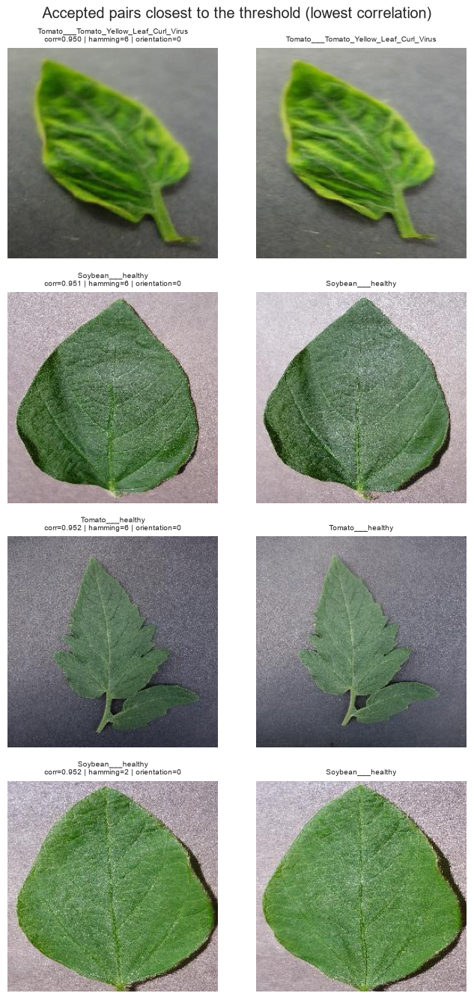

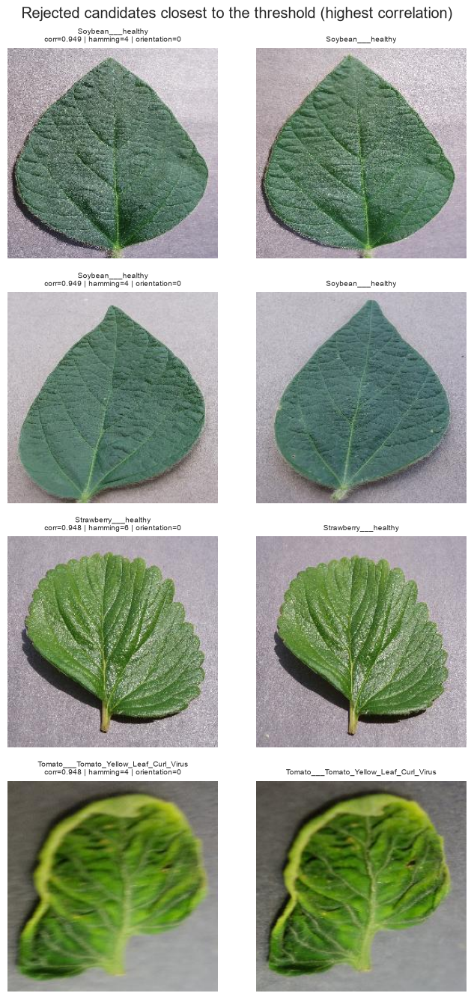

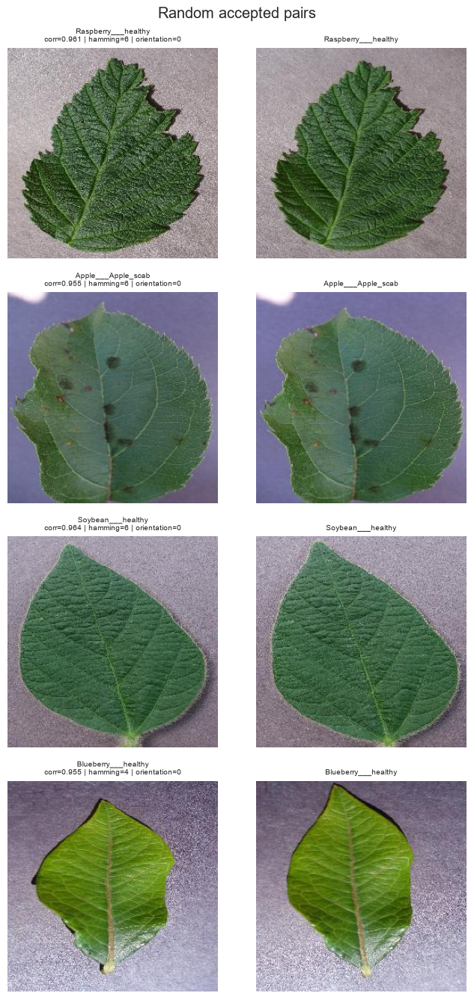

In [61]:
def show_pairs(pairs, title, n=4):
    pairs = pairs.head(n)
    if pairs.empty:
        print(f"{title}: no pairs to show")
        return
    fig, axes = plt.subplots(len(pairs), 2, figsize=(7, 3.4 * len(pairs)))
    axes = np.array(axes).reshape(len(pairs), 2)
    for r, (_, p) in enumerate(pairs.iterrows()):
        for c, key in enumerate(["i", "j"]):
            row = inv.loc[int(p[key])]
            with Image.open(row["path"]) as im:
                axes[r, c].imshow(im.convert("RGB"))
            caption = row["class"]
            if c == 0:
                caption += f"\ncorr={p['corr']:.3f} | hamming={int(p['hamming'])} | orientation={int(p['t'])}"
            axes[r, c].set_title(caption, fontsize=7)
            axes[r, c].axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


within_hamming = cand[cand["hamming"] <= PHASH_MAX_DISTANCE]
show_pairs(linked.sort_values("corr").head(4), "Accepted pairs closest to the threshold (lowest correlation)")
show_pairs(within_hamming[within_hamming["corr"] < THUMB_CORR_MIN].sort_values("corr", ascending=False).head(4),
           "Rejected candidates closest to the threshold (highest correlation)")
show_pairs(linked.sample(min(4, len(linked)), random_state=SEED) if len(linked) else linked,
           "Random accepted pairs")

### 15.2 Apply the Cross-Class Policy

In [62]:
inv["exclude_reason"] = ""
if CROSS_CLASS_GROUP_POLICY == "exclude":
    inv.loc[inv["cross_class_group"], "exclude_reason"] = "cross-class duplicate group (ambiguous label)"

exclusions = inv[inv["exclude_reason"] != ""].copy()
manifest = inv[inv["exclude_reason"] == ""].reset_index(drop=True)

print("Inventory images      :", f"{len(inv):,}")
print("Excluded from manifest:", f"{len(exclusions):,}")
print("Manifest images       :", f"{len(manifest):,}")
if len(exclusions):
    display(exclusions.groupby("class").size().rename("excluded").to_frame().T)

Inventory images      : 54,284
Excluded from manifest: 2
Manifest images       : 54,282


class,Tomato___Late_blight,Tomato___healthy
excluded,1,1


## 16. Stratified Group Split
### Objective

In [63]:
classes = sorted(manifest["class"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
manifest["label"] = manifest["class"].map(class_to_idx)

sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold = np.full(len(manifest), -1, dtype=int)
for k, (_, fold_idx) in enumerate(sgkf.split(manifest, manifest["label"], groups=manifest["group_id"])):
    fold[fold_idx] = k
manifest["fold"] = fold

n_test_folds = round(SPLIT_FRACTIONS["test"] * N_FOLDS)
n_val_folds = round(SPLIT_FRACTIONS["val"] * N_FOLDS)
assert n_test_folds >= 1 and n_val_folds >= 1 and n_test_folds + n_val_folds < N_FOLDS, "Adjust N_FOLDS or SPLIT_FRACTIONS."

fold_to_split = {}
for k in range(N_FOLDS):
    if k < n_test_folds:
        fold_to_split[k] = "test"
    elif k < n_test_folds + n_val_folds:
        fold_to_split[k] = "val"
    else:
        fold_to_split[k] = "train"
manifest["split"] = manifest["fold"].map(fold_to_split)

split_summary = manifest["split"].value_counts().reindex(["train", "val", "test"]).rename("images").to_frame()
split_summary["share_%"] = (split_summary["images"] / len(manifest) * 100).round(2)
split_summary["requested_%"] = [SPLIT_FRACTIONS[s] * 100 for s in split_summary.index]
display(split_summary)

,images,share_%,requested_%
split,,,
train,37996,70.0,70.0
val,8143,15.0,15.0
test,8143,15.0,15.0


No group or file is shared between splits.  Every class is present in train, val and test.
Smallest per-class count per split: {'train': 107, 'val': 23, 'test': 22}


split,train,val,test
min,69.400000,14.800000,14.500000
mean,69.984211,15.023684,14.997368
max,70.400000,15.400000,15.300000


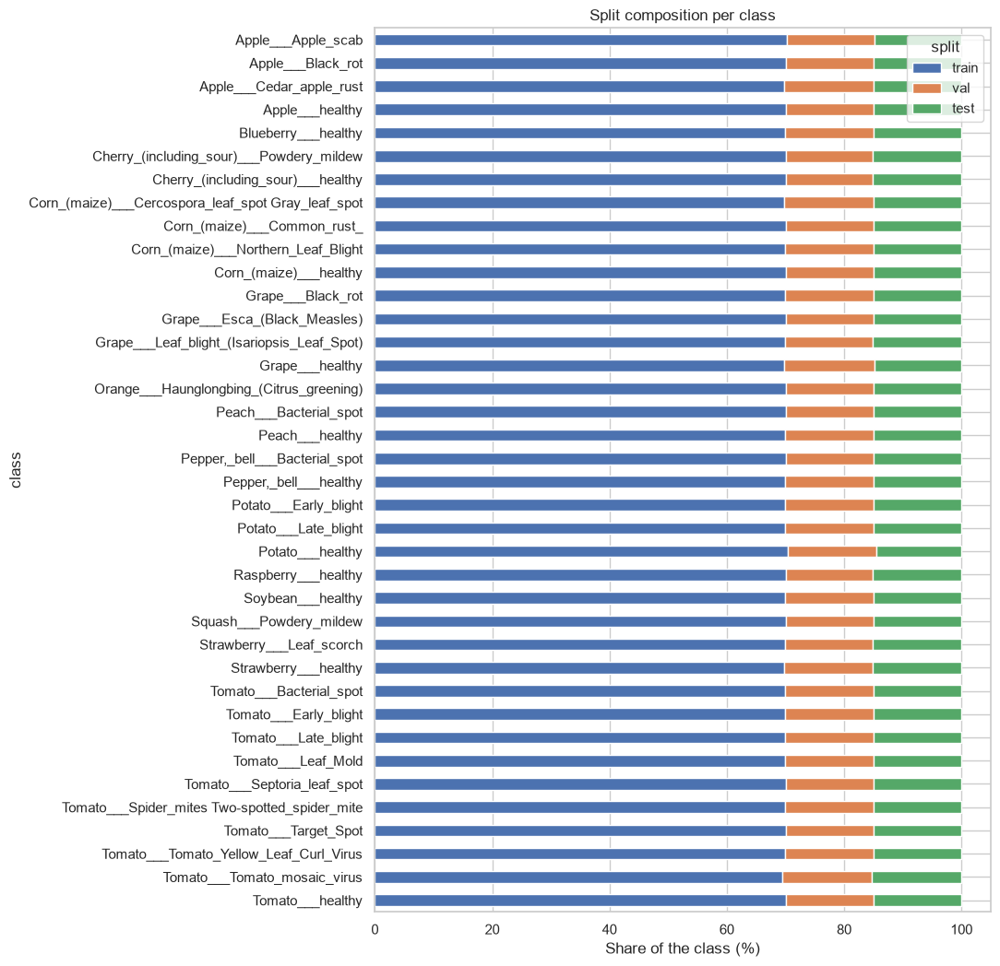

In [64]:
# ---- Leakage and coverage checks (these raise if violated) ----
assert (manifest["fold"] >= 0).all(), "Some images were not assigned to a fold."

groups_across_splits = manifest.groupby("group_id")["split"].nunique()
assert groups_across_splits.max() == 1, "A duplicate group is shared between splits."

hashes_across_splits = manifest.groupby("sha256")["split"].nunique()
assert hashes_across_splits.max() == 1, "A byte-identical file appears in more than one split."

coverage = pd.crosstab(manifest["class"], manifest["split"]).reindex(columns=["train", "val", "test"])
assert (coverage > 0).all().all(), "A class is missing from a split; reduce N_FOLDS."

print("No group or file is shared between splits.  Every class is present in train, val and test.")
print("Smallest per-class count per split:", coverage.min().to_dict())

share = coverage.div(coverage.sum(axis=1), axis=0) * 100
display(share.round(1).describe().loc[["min", "mean", "max"]])

ax = share.sort_index(ascending=False).plot(kind="barh", stacked=True, figsize=(11, max(6, len(classes) * 0.28)))
ax.set_xlabel("Share of the class (%)")
ax.set_title("Split composition per class")
plt.tight_layout()
plt.show()

## 17. Standardized Loading and Train-Only Statistics
### Objective
- Images are decoded, EXIF-orientation corrected and converted to RGB. A non-square image would be padded to a square instead of stretched; Pl
- Training transforms start from the native-resolution image (so random crops keep their detail); evaluation transforms resize to `IMG_SIZE`.
- A pretrained backbone must receive the statistics it was trained with, so the ImageNet values are the default. The dataset statistics are co

In [65]:
def load_square_rgb(path):
    """Native-resolution RGB image; padded (never stretched) if it is not square."""
    with Image.open(path) as im:
        img = ImageOps.exif_transpose(im).convert("RGB")
    if img.width != img.height:
        side = max(img.size)
        img = ImageOps.pad(img, (side, side), method=Image.Resampling.BICUBIC, color=PAD_COLOR)
    return img


def load_standardized(path, size=IMG_SIZE):
    """Image resized to the network input size (used for statistics and evaluation)."""
    img = load_square_rgb(path)
    if img.size != (size, size):
        img = img.resize((size, size), Image.Resampling.BICUBIC)
    return img


CORNER = max(4, IMG_SIZE // 14)     # 16 px for 224


def image_features(path):
    a = np.asarray(load_standardized(path), dtype=np.float64) / 255.0
    s1 = a.sum(axis=(0, 1))
    s2 = (a ** 2).sum(axis=(0, 1))
    patches = [a[:CORNER, :CORNER], a[:CORNER, -CORNER:], a[-CORNER:, :CORNER], a[-CORNER:, -CORNER:]]
    corner_means = np.concatenate([p.reshape(-1, 3).mean(axis=0) for p in patches])
    return s1, s2, corner_means


with ThreadPoolExecutor(max_workers=N_IO_THREADS) as pool:
    results = list(tqdm(pool.map(image_features, manifest["path"]), total=len(manifest), desc="Pass over images"))

channel_sum = np.stack([r[0] for r in results])
channel_sumsq = np.stack([r[1] for r in results])
corner_features = np.stack([r[2] for r in results])
print("Done:", len(results), "images")

Pass over images: 100%|██████████| 54282/54282 [02:02<00:00, 444.93it/s]


Done: 54282 images


In [66]:
train_mask = (manifest["split"] == "train").to_numpy()
n_pixels = float(IMG_SIZE * IMG_SIZE * train_mask.sum())

dataset_mean = channel_sum[train_mask].sum(axis=0) / n_pixels
dataset_std = np.sqrt(channel_sumsq[train_mask].sum(axis=0) / n_pixels - dataset_mean ** 2)

norm_stats = {
    "image_size": IMG_SIZE,
    "computed_on": "train split only",
    "n_train_images": int(train_mask.sum()),
    "dataset_mean_rgb": [float(x) for x in dataset_mean],
    "dataset_std_rgb": [float(x) for x in dataset_std],
    "imagenet_mean_rgb": list(IMAGENET_MEAN),
    "imagenet_std_rgb": list(IMAGENET_STD),
    "chosen": NORMALIZATION,
}
MEAN, STD = ((IMAGENET_MEAN, IMAGENET_STD) if NORMALIZATION == "imagenet"
             else (tuple(norm_stats["dataset_mean_rgb"]), tuple(norm_stats["dataset_std_rgb"])))

display(pd.DataFrame(
    {"dataset (train only)": [*dataset_mean, *dataset_std], "ImageNet": [*IMAGENET_MEAN, *IMAGENET_STD]},
    index=["mean R", "mean G", "mean B", "std R", "std G", "std B"],
).round(4))
print("Normalization used for the loaders:", NORMALIZATION)

,dataset (train only),ImageNet
mean R,0.4668,0.485
mean G,0.4895,0.456
mean B,0.4105,0.406
std R,0.1953,0.229
std G,0.1706,0.224
std B,0.2140,0.225


Normalization used for the loaders: imagenet


## 18. Shortcut Probe (Background and Capture Bias)
### Objective

In [67]:
val_mask = (manifest["split"] == "val").to_numpy()
corner_columns = [f"{pos}_{ch}" for pos in ("top_left", "top_right", "bottom_left", "bottom_right") for ch in "rgb"]
X_corner = pd.DataFrame(corner_features, columns=corner_columns)
y = manifest["label"].to_numpy()

probe = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)
probe.fit(X_corner[train_mask], y[train_mask])

probe_accuracy = float((probe.predict(X_corner[val_mask]) == y[val_mask]).mean())
chance = 1.0 / len(classes)
majority_label = pd.Series(y[train_mask]).mode().iloc[0]
majority_accuracy = float((y[val_mask] == majority_label).mean())

print("SHORTCUT PROBE (corner patches only, validation split)")
print("=" * 55)
print(f"Chance (uniform guess)      : {chance:.3f}")
print(f"Always-majority-class       : {majority_accuracy:.3f}")
print(f"Corner-patch random forest  : {probe_accuracy:.3f}")
if probe_accuracy > 3 * max(chance, majority_accuracy):
    print("-> The corners carry a strong class signal: expect shortcut learning; do not trust high in-dataset accuracy alone.")
elif probe_accuracy > 1.5 * max(chance, majority_accuracy):
    print("-> The corners carry a measurable class signal.")
else:
    print("-> No meaningful class signal in the corners.")

bias_probe = {"chance": chance, "majority_baseline": majority_accuracy,
              "corner_rf_val_accuracy": probe_accuracy, "patch_px": CORNER}

SHORTCUT PROBE (corner patches only, validation split)
Chance (uniform guess)      : 0.026
Always-majority-class       : 0.101
Corner-patch random forest  : 0.579
-> The corners carry a strong class signal: expect shortcut learning; do not trust high in-dataset accuracy alone.


## 19. Class Imbalance
### Objective
- **Inverse frequency:** weight proportional to `1 / count`, scaled so that a perfectly balanced dataset would give weight 1 to every class.
- **Effective number of samples** (Cui et al., 2019)

In [68]:
train_counts = manifest.loc[train_mask, "class"].value_counts().reindex(classes)
n_classes = len(classes)

w_inverse = train_counts.sum() / (n_classes * train_counts)

beta = 0.999
effective_num = (1.0 - np.power(beta, train_counts.to_numpy(dtype=float))) / (1.0 - beta)
w_effective = pd.Series(1.0 / effective_num, index=classes)
w_effective = w_effective / w_effective.sum() * n_classes

weights_table = pd.DataFrame({
    "train_images": train_counts,
    "w_inverse": w_inverse.round(3),
    "w_effective": w_effective.round(3),
})
display(weights_table.sort_values("train_images"))

print(f"Train imbalance ratio (largest / smallest class): {train_counts.max() / train_counts.min():.2f} : 1")

CLASS_WEIGHTS = {"inverse": w_inverse, "effective": w_effective, "none": None}[CLASS_WEIGHT_STRATEGY]
print("Loss weights:", CLASS_WEIGHT_STRATEGY, "| weighted sampler:", USE_WEIGHTED_SAMPLER)

,train_images,w_inverse,w_effective
Potato___healthy,107,9.345,4.112
Apple___Cedar_apple_rust,192,5.208,2.388
Peach___healthy,252,3.968,1.873
Tomato___Tomato_mosaic_virus,259,3.861,1.829
Raspberry___healthy,260,3.846,1.822
Grape___healthy,295,3.389,1.633
Strawberry___healthy,318,3.144,1.532
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,358,2.793,1.387
Apple___Black_rot,435,2.299,1.183
Apple___Apple_scab,443,2.257,1.166


Train imbalance ratio (largest / smallest class): 36.04 : 1
Loss weights: effective | weighted sampler: False


## 20. Augmentation Pipelines and DataLoaders
### Objective
**Training (online, random each epoch):**
**Validation / test:** resize to `IMG_SIZE`, normalize, nothing random.

In [69]:
# [torch]
import torch
import torchvision
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision.transforms import v2 as T

_tv = tuple(int(x) for x in torchvision.__version__.split("+")[0].split(".")[:2])
assert _tv >= (0, 16), "torchvision >= 0.16 is required (transforms.v2 with ToImage / ToDtype)."


class RandomDihedral:
    """Random choice among the 8 symmetries of the square (exact, no interpolation). Works on PIL images."""
    OPS = [None,
           Image.Transpose.ROTATE_90, Image.Transpose.ROTATE_180, Image.Transpose.ROTATE_270,
           Image.Transpose.FLIP_LEFT_RIGHT, Image.Transpose.FLIP_TOP_BOTTOM,
           Image.Transpose.TRANSPOSE, Image.Transpose.TRANSVERSE]

    def __call__(self, img):
        op = random.choice(self.OPS)
        return img if op is None else img.transpose(op)


train_transform = T.Compose([
    RandomDihedral(),
    T.ToImage(),
    T.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.9, 1.1), antialias=True),
    T.RandomApply([T.RandomRotation(degrees=15, fill=PAD_COLOR[0])], p=0.3),
    T.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.15, hue=0.02),
    T.RandomApply([T.GaussianBlur(kernel_size=5, sigma=(0.1, 1.5))], p=0.15),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(mean=list(MEAN), std=list(STD)),
    T.RandomErasing(p=0.25, scale=(0.02, 0.10), value=0),
])

eval_transform = T.Compose([
    T.ToImage(),
    T.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(mean=list(MEAN), std=list(STD)),
])


class PlantVillageDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths = frame["path"].tolist()
        self.labels = frame["label"].to_numpy()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        return self.transform(load_square_rgb(self.paths[index])), int(self.labels[index])


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2 ** 32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


frames = {s: manifest[manifest["split"] == s].reset_index(drop=True) for s in ("train", "val", "test")}
datasets = {
    "train": PlantVillageDataset(frames["train"], train_transform),
    "val": PlantVillageDataset(frames["val"], eval_transform),
    "test": PlantVillageDataset(frames["test"], eval_transform),
}

generator = torch.Generator().manual_seed(SEED)
loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=NUM_WORKERS > 0,
    worker_init_fn=seed_worker,
    generator=generator,
)

if USE_WEIGHTED_SAMPLER:
    per_sample = 1.0 / frames["train"]["class"].map(train_counts).to_numpy(dtype=float)
    sampler = WeightedRandomSampler(torch.as_tensor(per_sample, dtype=torch.double),
                                    num_samples=len(frames["train"]), replacement=True, generator=generator)
    train_loader = DataLoader(datasets["train"], sampler=sampler, **loader_kwargs)
else:
    train_loader = DataLoader(datasets["train"], shuffle=True, drop_last=True, **loader_kwargs)

val_loader = DataLoader(datasets["val"], shuffle=False, **loader_kwargs)
test_loader = DataLoader(datasets["test"], shuffle=False, **loader_kwargs)

class_weight_tensor = (None if CLASS_WEIGHTS is None
                       else torch.tensor(CLASS_WEIGHTS.reindex(classes).to_numpy(), dtype=torch.float32))

print({name: len(ds) for name, ds in datasets.items()}, "| classes:", len(classes))

{'train': 37996, 'val': 8143, 'test': 8143} | classes: 38


Batch: (64, 3, 224, 224) torch.float32 | labels: 1 to 37
Per-channel mean / std of the batch (should be near 0 / 1 for dataset stats, roughly so for ImageNet stats):
  mean: [-0.16   0.125 -0.122]  std: [0.93  0.821 1.015]


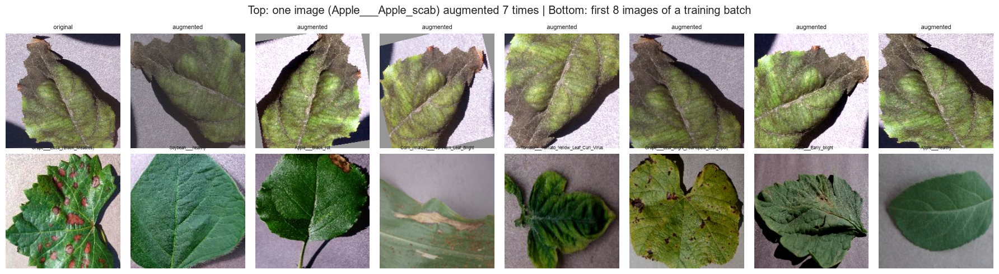

In [70]:
# [torch]
# Sanity checks on a real batch and a visual check of the augmentations.
images, labels = next(iter(train_loader))
print("Batch:", tuple(images.shape), images.dtype, "| labels:", int(labels.min()), "to", int(labels.max()))
print("Per-channel mean / std of the batch (should be near 0 / 1 for dataset stats, roughly so for ImageNet stats):")
print("  mean:", images.mean(dim=(0, 2, 3)).numpy().round(3), " std:", images.std(dim=(0, 2, 3)).numpy().round(3))
assert images.shape[1:] == (3, IMG_SIZE, IMG_SIZE) and torch.isfinite(images).all()

probe_img = load_square_rgb(frames["val"].loc[0, "path"])
assert torch.equal(eval_transform(probe_img), eval_transform(probe_img)), "Evaluation pipeline must be deterministic."


def denormalize(tensor):
    arr = tensor.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)
    return np.clip(arr, 0, 1)


fig, axes = plt.subplots(2, 8, figsize=(18, 5))
sample_path = frames["train"].loc[0, "path"]
sample_class = frames["train"].loc[0, "class"]
axes[0, 0].imshow(load_square_rgb(sample_path))
axes[0, 0].set_title("original", fontsize=8)
for k in range(1, 8):
    axes[0, k].imshow(denormalize(train_transform(load_square_rgb(sample_path))))
    axes[0, k].set_title("augmented", fontsize=8)
for k in range(8):
    axes[1, k].imshow(denormalize(images[k]))
    axes[1, k].set_title(classes[int(labels[k])], fontsize=6)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle(f"Top: one image ({sample_class}) augmented 7 times | Bottom: first 8 images of a training batch")
plt.tight_layout()
plt.show()

## 21. Export and Final Checks
- `splits.csv`
- `class_to_idx.json`: label mapping.
- `norm_stats.json`: dataset and ImageNet statistics, and which one is used.
- `class_weights.json`: both weighting schemes per class (computed on train).
- `exclusions.csv`: images left out of the manifest and why.
- `duplicate_groups.csv`: every group with two or more images.
- `grouping_sensitivity.csv`: how the grouping reacts to the thresholds.
- `bias_probe.json`: corner-patch probe result.
- `preprocessing_config.json`: every setting plus library versions.

In [71]:
def pkg_version(name):
    try:
        return md.version(name)
    except md.PackageNotFoundError:
        return None


split_columns = ["image_id", "path", "relative_path", "class", "label", "group_id", "group_size", "split", "sha256"]
split_columns += [c for c in ("width", "height") if c in manifest.columns]
manifest[split_columns].to_csv(PREP_DIR / "splits.csv", index=False)

(PREP_DIR / "class_to_idx.json").write_text(json.dumps(class_to_idx, indent=2), encoding="utf-8")
(PREP_DIR / "norm_stats.json").write_text(json.dumps(norm_stats, indent=2), encoding="utf-8")
(PREP_DIR / "class_weights.json").write_text(json.dumps({
    "computed_on": "train split only",
    "inverse": {c: float(w_inverse[c]) for c in classes},
    "effective_number_beta_0.999": {c: float(w_effective[c]) for c in classes},
    "chosen_strategy": CLASS_WEIGHT_STRATEGY,
    "weighted_sampler": USE_WEIGHTED_SAMPLER,
}, indent=2), encoding="utf-8")
(PREP_DIR / "bias_probe.json").write_text(json.dumps(bias_probe, indent=2), encoding="utf-8")

exclusions[["image_id", "path", "relative_path", "class", "group_id", "exclude_reason"]].to_csv(
    PREP_DIR / "exclusions.csv", index=False)

group_report = (
    inv[inv["group_size"] > 1]
    .groupby("group_id")
    .agg(group_size=("image_id", "size"),
         n_classes=("class", "nunique"),
         classes=("class", lambda s: " | ".join(sorted(s.unique()))),
         members=("relative_path", lambda s: " | ".join(sorted(s))))
    .reset_index()
)
group_report.to_csv(PREP_DIR / "duplicate_groups.csv", index=False)
sensitivity.to_csv(PREP_DIR / "grouping_sensitivity.csv", index=False)

config = {
    "created": datetime.now().isoformat(timespec="seconds"),
    "seed": SEED,
    "inputs": {"clean_inventory": str(CLEAN_INVENTORY_CSV)},
    "image": {"img_size": IMG_SIZE, "pad_color": list(PAD_COLOR)},
    "duplicate_groups": {"thumb_size": THUMB_SIZE, "phash_max_distance": PHASH_MAX_DISTANCE,
                         "thumb_corr_min": THUMB_CORR_MIN, "cross_class_policy": CROSS_CLASS_GROUP_POLICY},
    "split": {"fractions": SPLIT_FRACTIONS, "n_folds": N_FOLDS, "method": "StratifiedGroupKFold"},
    "normalization": NORMALIZATION,
    "class_weight_strategy": CLASS_WEIGHT_STRATEGY,
    "weighted_sampler": USE_WEIGHTED_SAMPLER,
    "batch_size": BATCH_SIZE,
    "counts": {"inventory": int(len(inv)), "excluded": int(len(exclusions)), "manifest": int(len(manifest)),
               **{s: int((manifest['split'] == s).sum()) for s in ("train", "val", "test")}},
    "versions": {"python": sys.version.split()[0],
                 **{n: pkg_version(n) for n in ("numpy", "pandas", "scipy", "scikit-learn", "Pillow", "torch", "torchvision")}},
}
(PREP_DIR / "preprocessing_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")

print("Saved files:")
for p in sorted(PREP_DIR.glob("*")):
    print("-", p.name, f"({p.stat().st_size / 1024:.1f} KB)")

Saved files:
- bias_probe.json (0.1 KB)
- class_to_idx.json (1.3 KB)
- class_weights.json (4.2 KB)
- duplicate_groups.csv (13.2 KB)
- exclusions.csv (0.7 KB)
- grouping_sensitivity.csv (0.4 KB)
- norm_stats.json (0.5 KB)
- preprocessing_config.json (1.0 KB)
- splits.csv (20427.1 KB)


In [72]:
# Re-read the exported split file and verify it independently of the in-memory objects.
saved = pd.read_csv(PREP_DIR / "splits.csv")

assert saved["split"].isin(["train", "val", "test"]).all()
assert saved.groupby("group_id")["split"].nunique().max() == 1, "Group shared between splits"
assert saved.groupby("sha256")["split"].nunique().max() == 1, "Identical file shared between splits"
assert saved["image_id"].is_unique
assert (pd.crosstab(saved["class"], saved["split"]) > 0).all().all(), "A class is missing from a split"
assert set(saved["label"]) == set(range(len(class_to_idx)))

print("PREPROCESSING SUMMARY")
print("=" * 50)
print("Inventory images        :", f"{len(inv):,}")
print("Excluded (label-unsafe) :", f"{len(exclusions):,}")
print("Usable images           :", f"{len(saved):,}")
print("Classes                 :", len(class_to_idx))
for s in ("train", "val", "test"):
    print(f"{s:<24}:", f"{(saved['split'] == s).sum():,}")
print("Normalization           :", NORMALIZATION)
print("Imbalance handling      :", "weighted sampler" if USE_WEIGHTED_SAMPLER else f"loss weights ({CLASS_WEIGHT_STRATEGY})")
print(f"Shortcut probe (corners): {probe_accuracy:.3f} vs chance {chance:.3f}")
print("\nAll leakage and coverage checks passed.")

PREPROCESSING SUMMARY
Inventory images        : 54,284
Excluded (label-unsafe) : 2
Usable images           : 54,282
Classes                 : 38
train                   : 37,996
val                     : 8,143
test                    : 8,143
Normalization           : imagenet
Imbalance handling      : loss weights (effective)
Shortcut probe (corners): 0.579 vs chance 0.026

All leakage and coverage checks passed.


### Using the output in the training notebook
```python
```
**Reporting reminders**
- Use the validation split for model selection and touch the test split once, at the end.
- Report macro-F1 and per-class recall next to accuracy.
- Because of the shortcut probe result in Section 18, treat in-dataset accuracy as an upper bound and, if possible, evaluate on external field